# Exploratory data analysis of the ACL and AO3 data

This notebook looks at the data as if for the first time: **what it contains, and how it changes
across the years**. Each section is a candidate analysis; the summary at the end lists them so you
can pick which ones to move into the pipeline.

* **Part 1: ACL Anthology papers** (S2ORC), 1999–2026
* **Part 2: AO3 fan fiction** (Tolkien fandoms), 2009–2026

It reads the raw data (`data/raw/`) and the outputs of the finished pipeline runs (`outputs/acl`,
`outputs/ao3`); nothing is recomputed that the pipeline already has. **No paper or story text is
printed**, only counts and statistics.

**Kernel:** the project's `.venv` (its matplotlib works; the anaconda base one currently does not).
Running everything takes a few minutes, mostly for reading the 3.6 GB of AO3 CSVs.

In [1]:
from pathlib import Path
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import LogNorm
from matplotlib.ticker import MaxNLocator

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from biber_drift.features.dimensions import BiberDimensionScorer  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 70)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10, "axes.labelsize": 9})
BREAK = 2022 + 11 / 12          # ChatGPT's release (30 Nov 2022), drawn as a dotted line
print("project root:", ROOT)

project root: /Users/amrgamea/Desktop/biber-drift


In [2]:
# ---------- helpers shared by both parts ----------
def int_years(*axes):
    """Whole-year ticks on the x axis (no 2012.5)."""
    for ax in axes:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))


def full_range(frame):
    """Reindex a year-indexed frame to every year, so gaps (missing years) break the lines."""
    years = frame.index.astype(int)
    return frame.reindex(range(years.min(), years.max() + 1))


def mean_ci(values, groups):
    """Per group: the mean of every column and the 95% CI half-width (normal approximation)."""
    grouped = values.groupby(groups)
    n = grouped.size().to_numpy()[:, None]
    return grouped.mean(), 1.96 * grouped.std(ddof=1) / np.sqrt(n)


def line_panels(mean, half, columns, titles=None, ncols=4, ylabel="", panel=(3.6, 2.5), mark_break=True):
    """Small multiples: one panel per column, mean line with a shaded 95% CI."""
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel[0] * ncols, panel[1] * nrows), squeeze=False)
    x = mean.index.to_numpy(dtype=float)
    for ax, column, title in zip(axes.flat, columns, titles or columns):
        m = mean[column].to_numpy(dtype=float)
        ax.plot(x, m, "-o", ms=3, lw=1.5, color="tab:blue")
        if half is not None:
            h = half[column].to_numpy(dtype=float)
            ax.fill_between(x, m - h, m + h, color="tab:blue", alpha=0.2, lw=0)
        if mark_break:
            ax.axvline(BREAK, color="0.5", ls=":", lw=1)
        ax.set_title(title, fontsize=9)
        ax.set_ylabel(ylabel, fontsize=8)
        ax.tick_params(labelsize=8)
        int_years(ax)
    for ax in list(axes.flat)[len(columns):]:
        ax.axis("off")
    fig.tight_layout()
    return fig


def feature_unit(name):
    return {"f_43_type_token": "type/token ratio", "f_44_mean_word_length": "characters"}.get(name, "per 1,000 words")


def yearly_z(z, years, valid_years):
    """Mean standardised value of every feature per year (valid years only)."""
    keep = years.isin(valid_years)
    return z[keep].groupby(years[keep]).mean()


def trend_table(yearly):
    """Linear change per decade (in standard deviations) and Spearman correlation with the year."""
    x = yearly.index.to_numpy(dtype=float)
    slope = yearly.apply(lambda col: np.polyfit(x, col.to_numpy(dtype=float), 1)[0] * 10)
    rho = yearly.apply(lambda col: pd.Series(col.to_numpy()).corr(pd.Series(x), method="spearman"))
    return pd.DataFrame({"change per decade (sd)": slope, "Spearman rho with year": rho})


def trend_heatmap(yearly, title):
    table = trend_table(yearly).sort_values("Spearman rho with year", ascending=False)
    data = yearly[table.index].T
    data.index = [f"{name}  ({rho:+.2f})" for name, rho in table["Spearman rho with year"].items()]
    fig, ax = plt.subplots(figsize=(0.42 * len(yearly) + 4.5, 0.2 * len(data) + 1.6))
    sns.heatmap(data, cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, ax=ax,
                cbar_kws={"label": "yearly mean (standard deviations of all documents)", "shrink": 0.5})
    ax.set_xlabel("year")
    ax.set_ylabel("")
    ax.set_title(title)
    ax.tick_params(axis="y", labelsize=7)
    ax.tick_params(axis="x", labelsize=8, rotation=90)
    fig.tight_layout()
    return fig


def classical_mds(squared_distances, k=2):
    """Coordinates whose distances approximate the given squared distances (classical MDS)."""
    d2 = squared_distances.to_numpy(dtype=float)
    n = len(d2)
    centre = np.eye(n) - np.ones((n, n)) / n
    b = -0.5 * centre @ d2 @ centre
    values, vectors = np.linalg.eigh(b)
    order = np.argsort(values)[::-1][:k]
    coords = vectors[:, order] * np.sqrt(np.maximum(values[order], 0))
    return coords, values[order] / values[values > 0].sum()


def pca(z, k=2):
    x = z.to_numpy(dtype=float)
    x = x - x.mean(axis=0)
    values, vectors = np.linalg.eigh(x.T @ x / (len(x) - 1))
    order = np.argsort(values)[::-1]
    values, vectors = values[order], vectors[:, order]
    names = [f"PC{i + 1}" for i in range(k)]
    scores = pd.DataFrame(x @ vectors[:, :k], index=z.index, columns=names)
    loadings = pd.DataFrame(vectors[:, :k], index=z.columns, columns=names)
    return scores, loadings, values / values.sum()


def plot_trajectory(points, labels, title, xlabel, ylabel):
    fig, ax = plt.subplots(figsize=(7.5, 6))
    ax.plot(points[:, 0], points[:, 1], color="0.75", lw=1, zorder=1)
    scatter = ax.scatter(points[:, 0], points[:, 1], c=np.asarray(labels, dtype=float), cmap="viridis", s=50, zorder=2)
    for (x, y), label in zip(points, labels):
        ax.annotate(str(label), (x, y), xytext=(4, 3), textcoords="offset points", fontsize=8)
    fig.colorbar(scatter, ax=ax, label="year")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    fig.tight_layout()
    return fig


def mmd_figures(results, name):
    """Heatmap of the year x year MMD^2 matrix, consecutive-year effects and a 2-D map of the years."""
    matrix = pd.read_csv(results / "mmd_by_year_matrix.csv", index_col=0)
    matrix.index = matrix.index.astype(int)
    matrix.columns = matrix.columns.astype(int)
    pairwise = pd.read_csv(results / "mmd_by_year_pairwise.csv").set_index(["cohort_a", "cohort_b"])
    pooled = pd.read_csv(results / "mmd_by_year_pooled_baseline.csv").iloc[0]

    fig, ax = plt.subplots(figsize=(0.5 * len(matrix) + 3, 0.45 * len(matrix) + 2))
    sns.heatmap(matrix * 1000, annot=True, fmt=".1f", annot_kws={"size": 6}, cmap="viridis", ax=ax,
                cbar_kws={"label": "MMD² × 1000"})
    ax.set_title(f"{name}: how different is every pair of years? (MMD², fixed samples of {int(pooled['sample_size'])})")
    ax.set_xlabel("")
    ax.set_ylabel("")
    fig.tight_layout()
    plt.show()

    years = list(matrix.index)
    steps = [(a, b) for a, b in zip(years[:-1], years[1:])]
    effects = pd.DataFrame([{"step": f"{a}→{b}", "effect": pairwise.loc[(a, b), "effect_vs_pooled_baseline"],
                             "p_adjusted": pairwise.loc[(a, b), "p_adjusted"]} for a, b in steps])
    threshold = (pooled["ci_upper"] - pooled["mean_mmd2"]) / pooled["std_mmd2"]
    fig, ax = plt.subplots(figsize=(0.5 * len(effects) + 3, 3.6))
    colors = np.where(effects["p_adjusted"] < 0.05, "tab:blue", "0.7")
    ax.bar(effects["step"], effects["effect"], color=colors)
    ax.axhline(threshold, color="tab:orange", ls="--", lw=1, label="upper 95% bound of chance (pooled baseline)")
    ax.set_ylabel("effect vs pooled baseline (sd)")
    ax.set_title(f"{name}: change from one year to the next (blue: adjusted p < 0.05)")
    ax.tick_params(axis="x", rotation=90, labelsize=8)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

    coords, explained = classical_mds(matrix)
    plot_trajectory(coords, years, f"{name}: map of the years (classical MDS of MMD²; "
                    f"axes explain {explained[0]:.0%} and {explained[1]:.0%})", "axis 1", "axis 2")
    plt.show()
    return matrix, effects


def diversity_figure(results, name):
    variance = pd.read_csv(results / "variance.csv")
    variance = variance[(variance["grouping"] == "year") & (variance["cohort"] != "all documents")].copy()
    variance["year"] = variance["cohort"].astype(int)
    variance = variance.set_index("year").sort_index()
    total = pd.read_csv(results / "variance.csv").query("grouping == 'year' and cohort == 'all documents'").iloc[0]
    baselines = pd.read_csv(results / "mmd_by_year_baselines.csv").set_index("cohort").sort_index()

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    v = full_range(variance)
    axes[0].plot(v.index, v["mean_total_variance"], "-o", ms=3, color="tab:blue", label=f"resampled at n = {int(total['sample_size'])}")
    axes[0].fill_between(v.index, v["ci_lower"], v["ci_upper"], color="tab:blue", alpha=0.2, lw=0)
    axes[0].axhline(total["total_variance_all_documents"], color="0.5", ls="--", lw=1, label="whole corpus")
    axes[0].set_title(f"{name}: total variance of the standardised features per year")
    axes[0].set_ylabel("sum of feature variances")
    axes[0].legend(fontsize=8)
    b = full_range(baselines)
    axes[1].plot(b.index, b["mean_mmd2"] * 1000, "-o", ms=3, color="tab:green")
    axes[1].fill_between(b.index, b["ci_lower"] * 1000, b["ci_upper"] * 1000, color="tab:green", alpha=0.2, lw=0)
    axes[1].set_title(f"{name}: MMD² between two random halves of the same year")
    axes[1].set_ylabel("MMD² × 1000")
    for ax in axes:
        ax.axvline(BREAK, color="0.5", ls=":", lw=1)
        int_years(ax)
    fig.tight_layout()
    plt.show()

In [3]:
# ---------- helpers for the feature-change sections and the pipeline figures ----------
import yaml
from IPython.display import Image


def key_year_steps(run_dir):
    """The comparisons of a run's feature_change analysis: consecutive key years, then the full span."""
    years = sorted(yaml.safe_load((run_dir / "config.yaml").read_text())["feature_change"]["years"])
    steps = list(zip(years[:-1], years[1:]))
    return steps + [(years[0], years[-1])] if len(years) > 2 else steps


def feature_change_table(run_dir, a, b):
    """Means, signed changes and the scaled scores of every feature for one comparison."""
    folder = run_dir / "results" / "feature_change" / "all"
    scaled = pd.read_csv(folder / f"scaled_{a}_to_{b}.csv", index_col="feature")
    changes = pd.read_csv(folder / "changes.csv", index_col="feature")
    return pd.DataFrame({
        f"mean {a}": scaled[f"{a}_mean"], f"mean {b}": scaled[f"{b}_mean"],
        "absolute change": changes[f"change_{a}_to_{b}"], "relative change (%)": changes[f"pct_{a}_to_{b}"],
        "absolute (min-max)": scaled["absolute_scaled"], "relative (min-max)": scaled["relative_scaled"],
        "combined score": scaled["combined_score"],
    })


def show_feature_change(run_dir, name, top=10):
    """For every comparison: the top features by absolute, relative and combined change."""
    titles = {"absolute change": "absolutely (in the feature's own unit)",
              "relative change (%)": "relatively (% of the earlier mean)",
              "combined score": "combined (0.5 × scaled absolute + 0.5 × scaled relative)"}
    for a, b in key_year_steps(run_dir):
        table = feature_change_table(run_dir, a, b)
        rankings = {column: (table[column].nlargest(top) if column == "combined score"
                             else table[column].abs().nlargest(top)).index for column in titles}
        display(Markdown(f"#### {name}: {a} → {b}"))
        fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
        for ax, (column, index) in zip(axes, rankings.items()):
            values = table.loc[index, column][::-1]
            increased = table.loc[index, "absolute change"][::-1] >= 0
            ax.barh(values.index, values.values, color=np.where(increased, "tab:blue", "tab:orange"))
            ax.axvline(0, color="0.4", lw=0.8)
            ax.set_title(f"Top {top} features that changed {titles[column]}", fontsize=9)
            ax.set_xlabel(column)
            ax.tick_params(axis="y", labelsize=8)
        handles = [plt.Rectangle((0, 0), 1, 1, color="tab:blue"), plt.Rectangle((0, 0), 1, 1, color="tab:orange")]
        fig.legend(handles, ["mean increased", "mean decreased"], loc="lower center", ncol=2, frameon=False,
                   bbox_to_anchor=(0.5, -0.03))
        fig.tight_layout(rect=(0, 0.04, 1, 1))
        plt.show()
        display(pd.DataFrame({
            "absolutely": [f"{f} ({table.at[f, 'absolute change']:+.2f})" for f in rankings["absolute change"]],
            "relatively": [f"{f} ({table.at[f, 'relative change (%)']:+.0f}%)" for f in rankings["relative change (%)"]],
            "combined": [f"{f} ({table.at[f, 'combined score']:.2f})" for f in rankings["combined score"]],
        }, index=pd.RangeIndex(1, top + 1, name="rank")))


def _shift_caption(path):
    years = path.stem.split("_")[2:]
    if len(years) > 2:
        return "Largest per-feature shifts (Wasserstein distance) for each key-year step and the full span."
    return "Older version of this figure (first vs last year only), left over from an earlier pipeline run."


FIGURE_GROUPS = [
    ("Corpus and quality", {
        "documents_by_year.png": "Documents per year after cleaning and the 400-word window.",
        "quality_metrics.png": "Distribution of the seven malformed-text metrics (dashed line: flag threshold).",
        "quality_flags_by_year.png": "Share of documents carrying each quality flag, per year."}),
    ("How different are the years? (MMD²)", {
        "mmd_by_year_heatmap.png": "Pairwise MMD² between the years (fixed samples per year).",
        "mmd_by_era_group_heatmap.png": "Pairwise MMD² between era × venue-tier cohorts (fixed samples of 50)."}),
    ("Sample-size stability (choosing n)", {
        "sample_size_stability_all.png": "MMD² between two random halves against the sample size, whole corpus.",
        "sample_size_stability_era.png": "The same per era.",
        "sample_size_stability_group.png": "The same per venue tier.",
        "sample_size_stability_era_group.png": "The same per era × venue tier."}),
    ("Biber dimensions", {
        "biber_dimensions_by_year.png": "Dimension scores per year (violins).",
        "biber_dimensions_by_era.png": "Dimension scores per era (violins).",
        "biber_dimensions_by_group.png": "Dimension scores per venue tier.",
        "biber_dimensions_by_era_group.png": "Dimension scores per era and venue tier."}),
    ("Feature shifts", {"feature_shifts_*.png": None}),
    ("Diversity", {
        "variance_by_year.png": "Total variance of the standardised features per year.",
        "variance_by_era_group.png": "Total variance per era × venue tier."}),
    ("Interrupted time series", {
        "trend_level_changes.png": "Largest jumps at the break beyond the pre-break trend (features).",
        "trend_series_dimensions.png": "Total variance and the seven dimensions with the fitted segmented trend.",
        "trend_series_features.png": "The eight features that departed most from their pre-break trend."}),
]


def show_pipeline_figures(figure_dir, width=1000):
    """Every figure of a run's report stage, grouped by topic, with a caption."""
    shown = set()
    for title, captions in FIGURE_GROUPS:
        files = [(path, caption or _shift_caption(path))
                 for pattern, caption in captions.items() for path in sorted(figure_dir.glob(pattern))]
        if not files:
            continue
        display(Markdown(f"### {title}"))
        for path, caption in files:
            display(Markdown(f"`{path.name}`: {caption}"))
            display(Image(filename=str(path), width=width))
            shown.add(path.name)
    others = sorted(p for p in figure_dir.glob("*.png") if p.name not in shown)
    if others:
        display(Markdown("### Other figures"))
        for path in others:
            display(Markdown(f"`{path.name}`"))
            display(Image(filename=str(path), width=width))

---
# Part 1: ACL Anthology papers

## 1.1 What the raw data looks like
`data/raw/acl/Dataset_all.csv`: one row per paper, as extracted from S2ORC (section texts plus
metadata from the Semantic Scholar API).

In [4]:
acl_raw = pd.read_csv(ROOT / "data/raw/acl/Dataset_all.csv", dtype={"id": str})
SECTIONS = ["abstract", "introduction", "methods", "results", "discussion"]
for section in SECTIONS:
    acl_raw[section] = acl_raw[section].fillna("").astype(str)
    acl_raw[f"{section}_words"] = acl_raw[section].str.split().str.len()
acl_raw["year"] = pd.to_numeric(acl_raw["year"], errors="coerce")
print(f"{len(acl_raw):,} papers, {acl_raw.shape[1] - len(SECTIONS)} columns, years {acl_raw['year'].min():.0f}–{acl_raw['year'].max():.0f}")

rows = []
for column in ["id", "title", "authors", "year", "venue", "citation_count", "source_year"] + SECTIONS:
    values = acl_raw[column]
    filled = values.notna() & values.astype(str).str.strip().ne("")
    if column in SECTIONS:
        content = f"text; median {acl_raw.loc[filled, column + '_words'].median():.0f} words where present"
    else:
        content = str(values.dropna().iloc[0])[:60] if values.notna().any() else "(empty)"
    rows.append({"column": column, "dtype": str(values.dtype), "filled (%)": round(100 * filled.mean(), 1),
                 "example / content": content})
display(pd.DataFrame(rows).set_index("column"))

43,876 papers, 12 columns, years 1999–2026


,dtype,filled (%),example / content
column,,,
id,str,100.0,C00-1031
title,float64,0.0,(empty)
authors,str,100.0,"D. Cristea, Nancy Ide, D. Marcu, V. Tablan"
year,float64,100.0,2000.0
venue,str,97.6,International Conference on Computational Linguistics
citation_count,float64,99.6,18.0
source_year,int64,100.0,2000
abstract,str,99.4,text; median 130 words where present
introduction,str,97.8,text; median 494 words where present


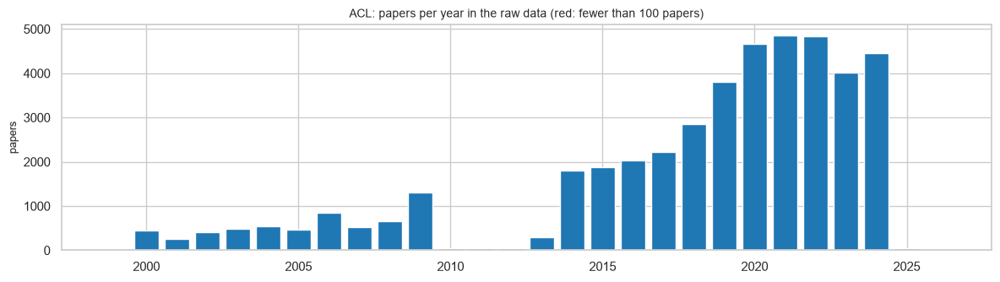

years with < 100 papers: {1999: 2, 2010: 45, 2011: 47, 2012: 48, 2025: 41, 2026: 14}


In [5]:
counts = acl_raw["year"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(counts.index.astype(int), counts.values, color=np.where(counts.values < 100, "tab:red", "tab:blue"))
ax.set_title("ACL: papers per year in the raw data (red: fewer than 100 papers)")
ax.set_ylabel("papers")
fig.tight_layout()
plt.show()
ACL_RAW_YEARS = counts[counts >= 100].index.astype(int)
print("years with < 100 papers:", {int(y): int(n) for y, n in counts[counts < 100].items()})

<!-- obs:acl_raw_years -->
**What we see:**
- **43,876 papers**, but coverage is uneven: 260–1,300 papers a year in 2000–2009, only **45–48 a year in
  2010–2012** (a gap in the S2ORC extraction, not in the Anthology), a jump from 2013, a peak of ~4,850 in
  2021–2022, ~4,000 in 2023 and ~4,450 in 2024. **2025–2026 are almost empty** (41 and 14 papers): the
  S2ORC release predates most of them.
- `title` is empty for every paper (the metadata backfill never fills it); 2.4% have no venue.
- Methods and results sections exist in only about half of the papers (54%); abstract, introduction and
  discussion in 94–99%.
- All year-by-year plots below use the years with at least 100 papers: 2000–2009 and 2013–2024.

673 distinct venue strings; the 12 most common:


,papers
venue,
Annual Meeting of the Association for Computational Linguistics,7329
Conference on Empirical Methods in Natural Language Processing,7010
North American Chapter of the Association for Computational Linguistics,3396
International Workshop on Semantic Evaluation,2550
International Conference on Computational Linguistics,1743
Conference of the European Chapter of the Association for Computational Linguistics,1528
Findings,1509
International Conference on Language Resources and Evaluation,1230
(missing),1046


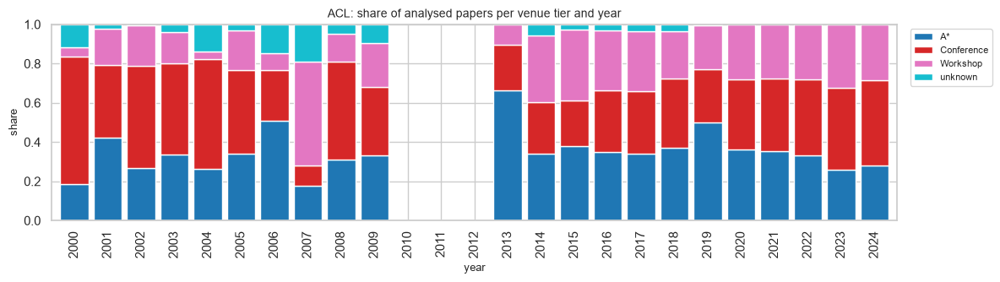

In [6]:
venues = acl_raw["venue"].fillna("(missing)").value_counts()
print(f"{acl_raw['venue'].nunique():,} distinct venue strings; the 12 most common:")
display(venues.head(12).rename("papers").to_frame())

acl_corpus = pd.read_parquet(ROOT / "outputs/acl/corpus/corpus.parquet", columns=["year", "venue_tier"])
tiers = pd.crosstab(acl_corpus["year"], acl_corpus["venue_tier"].fillna("unknown"), normalize="index")
tiers = full_range(tiers.loc[acl_corpus["year"].value_counts().loc[lambda s: s >= 100].index.sort_values()])
ax = tiers.plot(kind="bar", stacked=True, figsize=(12, 3.5), width=0.85, colormap="tab10")
ax.set_title("ACL: share of analysed papers per venue tier and year")
ax.set_ylabel("share")
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

<!-- obs:acl_venues -->
**What we see:**
- 673 distinct venue strings; ACL, EMNLP, NAACL, SemEval and COLING contribute most papers.
- The tier mix changes: 2013 is mostly A* (66%), 2014–2018 have many workshop papers (24–36%), and since
  2020 the mix is stable (A* 26–36%, Conference 36–45%, Workshop 28–33%).
- **2007 is unusual**: 53% workshop papers (SemEval-2007, WMT, BioNLP) and 19% with no venue. This is why
  2007 stands out in every style analysis below.

## 1.2 How the papers themselves changed
Section coverage, length, team size, citations and topics, year by year (years with at least 100
raw papers).

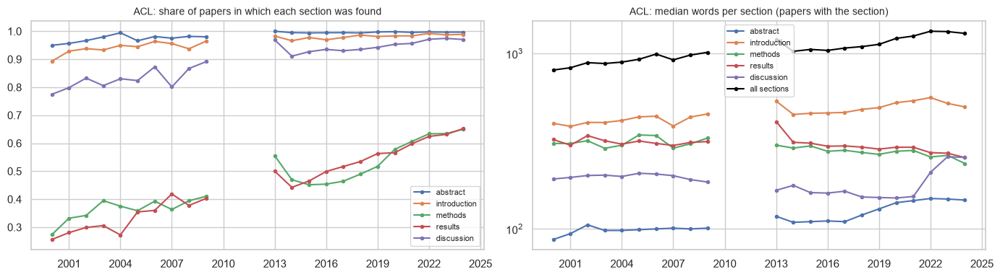

In [7]:
raw = acl_raw[acl_raw["year"].isin(ACL_RAW_YEARS)].copy()
coverage = full_range(raw.groupby("year")[[f"{s}_words" for s in SECTIONS]].agg(lambda s: (s > 0).mean()))
length = full_range(raw.groupby("year")[[f"{s}_words" for s in SECTIONS]].agg(lambda s: s[s > 0].median()))
raw["all_sections_words"] = raw[[f"{s}_words" for s in SECTIONS]].sum(axis=1)
length["all sections"] = full_range(raw.groupby("year")["all_sections_words"].median())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for section in SECTIONS:
    axes[0].plot(coverage.index, coverage[f"{section}_words"], "-o", ms=3, label=section)
    axes[1].plot(length.index, length[f"{section}_words"], "-o", ms=3, label=section)
axes[1].plot(length.index, length["all sections"], "-o", ms=3, color="black", label="all sections")
axes[0].set_title("ACL: share of papers in which each section was found")
axes[1].set_title("ACL: median words per section (papers with the section)")
axes[1].set_yscale("log")
for ax in axes:
    ax.legend(fontsize=8)
    int_years(ax)
fig.tight_layout()
plt.show()

<!-- obs:acl_sections -->
**What we see:**
- Abstracts are found in 95–100% of papers in every year, introductions in 89–99% and a discussion or
  conclusion in 78–97%. **Methods and results sections are found in only 26–42% of 2000s papers, rising to
  65% by 2024**:
  papers use more standard section headings (or the PDFs extract better).
- Papers get longer: the median of all sections together grows from ~800 words (2000) to ~1,330 (2022).
  Abstracts grow from ~85 to ~150 words, introductions from ~400 to ~560 (2022) and back to ~500 (2024).

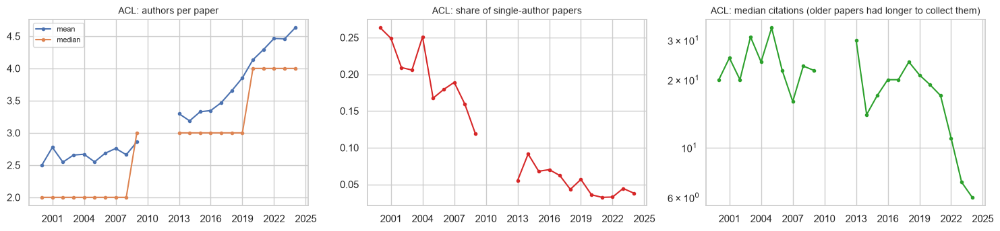

In [8]:
authors = raw["authors"].fillna("").astype(str).str.strip("[]")
raw["n_authors"] = authors.apply(lambda s: len([a for a in s.split(",") if a.strip(" '\"")]))
team = full_range(raw[raw["n_authors"] > 0].groupby("year")["n_authors"].agg(["mean", "median", lambda s: (s == 1).mean()]))
team.columns = ["mean", "median", "single-author share"]
citations = full_range(raw.groupby("year")["citation_count"].median().to_frame("median citations"))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(team.index, team["mean"], "-o", ms=3, label="mean")
axes[0].plot(team.index, team["median"], "-o", ms=3, label="median")
axes[0].set_title("ACL: authors per paper")
axes[0].legend(fontsize=8)
axes[1].plot(team.index, team["single-author share"], "-o", ms=3, color="tab:red")
axes[1].set_title("ACL: share of single-author papers")
axes[2].plot(citations.index, citations["median citations"], "-o", ms=3, color="tab:green")
axes[2].set_yscale("log")
axes[2].set_title("ACL: median citations (older papers had longer to collect them)")
int_years(*axes)
fig.tight_layout()
plt.show()

<!-- obs:acl_authors -->
**What we see:**
- **Teams grow steadily**: from 2.5 authors per paper on average (2000) to 4.6 (2024); the median from 2 to 4.
  Single-author papers fall from 26% to 4%.
- Median citations fall for recent years only because recent papers have had less time to be cited.

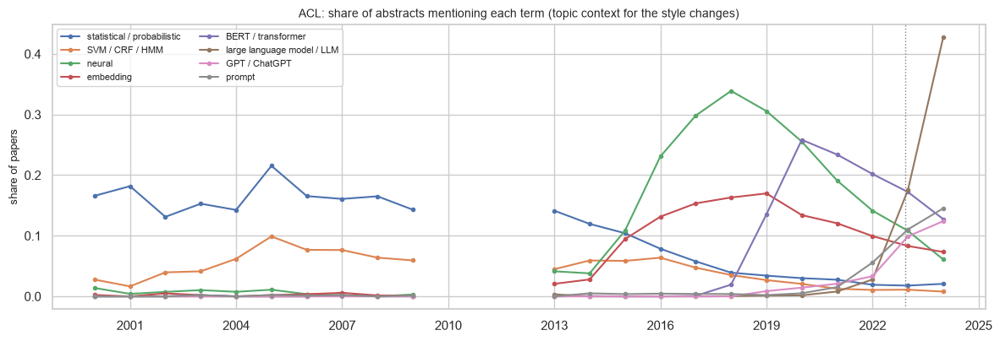

In [9]:
TERMS = {
    "statistical / probabilistic": r"\bstatistical\b|\bprobabilistic\b",
    "SVM / CRF / HMM": r"\bsvms?\b|support vector|\bcrfs?\b|conditional random field|\bhmms?\b|hidden markov",
    "neural": r"\bneural\b",
    "embedding": r"\bembeddings?\b|word2vec|\bglove\b",
    "BERT / transformer": r"\bbert\b|transformer",
    "large language model / LLM": r"large language models?|\bllms?\b",
    "GPT / ChatGPT": r"\bgpt|chatgpt",
    "prompt": r"\bprompt(?:s|ing|ed)?\b",
}
with_abstract = raw[raw["abstract_words"] > 0]
abstracts = with_abstract["abstract"].str.lower()
shares = full_range(pd.DataFrame({term: abstracts.str.contains(pattern, regex=True) for term, pattern in TERMS.items()})
                    .groupby(with_abstract["year"]).mean())
fig, ax = plt.subplots(figsize=(12, 4.2))
for term in TERMS:
    ax.plot(shares.index, shares[term], "-o", ms=3, label=term)
ax.axvline(BREAK, color="0.5", ls=":", lw=1)
ax.set_title("ACL: share of abstracts mentioning each term (topic context for the style changes)")
ax.set_ylabel("share of papers")
ax.legend(fontsize=8, ncol=2)
int_years(ax)
fig.tight_layout()
plt.show()

<!-- obs:acl_topics -->
**What we see:**
- Clear topic waves: "statistical / probabilistic" in 15–21% of 2000s abstracts, 2% in 2024; SVM/CRF/HMM
  peak around 2005 (~10%); **"neural"** from 4% (2013) to **34% (2018)**, then down to 6%; embeddings peak in
  2019 (17%); **BERT / transformer peak in 2020 (26%)**; **"large language model / LLM" from 1% (2021) to 18%
  (2023) and 43% (2024)**, with "prompt" (15%) and GPT (12%) in 2024.
- Topic matters for interpreting style: the 2023–24 style change coincides with a shift towards papers
  *about* LLMs.

## 1.3 From raw data to the analysed corpus
What the cleaning, the quality diagnostics and the 400-word window kept (outputs of the `prepare`
stage).

,step,description,documents_changed,documents_dropped,documents_remaining
0,sentence_spacing,missing space after sentence end,12400,0,43874
1,whitespace,collapse whitespace,1248,0,43874
2,boilerplate,"boilerplate (licence, arXiv stamp, \n)",2031,0,43874
3,urls,URLs and e-mails,7164,0,43874
4,citations,citations,40746,0,43874
5,footnotes,footnote markers,1356,0,43874
6,symbols,symbol markers,3051,0,43874
7,number_runs,table number runs,94,0,43874
8,tidy,tidy spaces / punctuation,40661,0,43874
9,duplicates,duplicate texts,0,164,43710


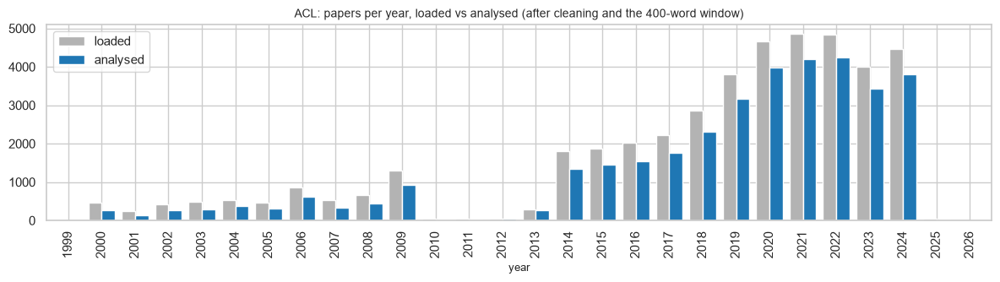

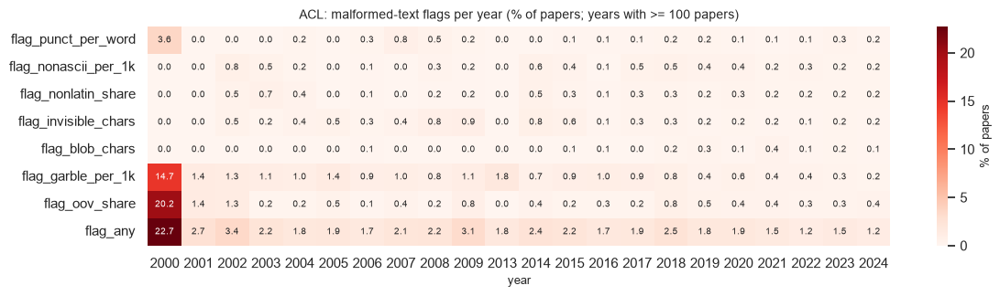

In [10]:
CORPUS = ROOT / "outputs/acl/corpus"
display(pd.read_csv(CORPUS / "cleaning_report.csv")[["step", "description", "documents_changed", "documents_dropped", "documents_remaining"]])
before = pd.read_csv(CORPUS / "documents_by_year_raw.csv", index_col=0).iloc[:, 0]
after = pd.read_csv(CORPUS / "documents_by_year.csv", index_col=0).iloc[:, 0]
kept = pd.DataFrame({"loaded": before, "analysed": after}).fillna(0)
ax = kept.plot(kind="bar", figsize=(12, 3.5), width=0.8, color=["0.7", "tab:blue"])
ax.set_title("ACL: papers per year, loaded vs analysed (after cleaning and the 400-word window)")
plt.tight_layout()
plt.show()
flags = pd.read_csv(CORPUS / "quality_flags_by_year.csv", index_col=0)
flags = flags[flags["documents"] >= 100].drop(columns="documents")
fig, ax = plt.subplots(figsize=(12, 3.4))
sns.heatmap(flags.T, annot=True, fmt=".1f", annot_kws={"size": 7}, cmap="Reds", ax=ax, cbar_kws={"label": "% of papers"})
ax.set_title("ACL: malformed-text flags per year (% of papers; years with >= 100 papers)")
fig.tight_layout()
plt.show()

<!-- obs:acl_prepare -->
**What we see:**
- Of 43,874 loaded papers, **35,664 (81%) are analysed**. Most losses come from the 400-word window (6,667
  papers with fewer than 400 words in abstract + introduction) and from papers under 200 words (1,379).
  Citation removal changed 93% of the papers.
- Malformed-text flags: **22.7% of the 2000 papers** (OCR'd scans), 1–3% in every other year.

## 1.4 The 67 Biber features across the years
Every feature is standardised with the run's single scaler (`results/reference_scaler.csv`), so a
yearly mean of +0.3 means "0.3 standard deviations above the average paper". Years with fewer than
100 analysed papers are left out.

35,664 papers x 67 features; years shown: 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024


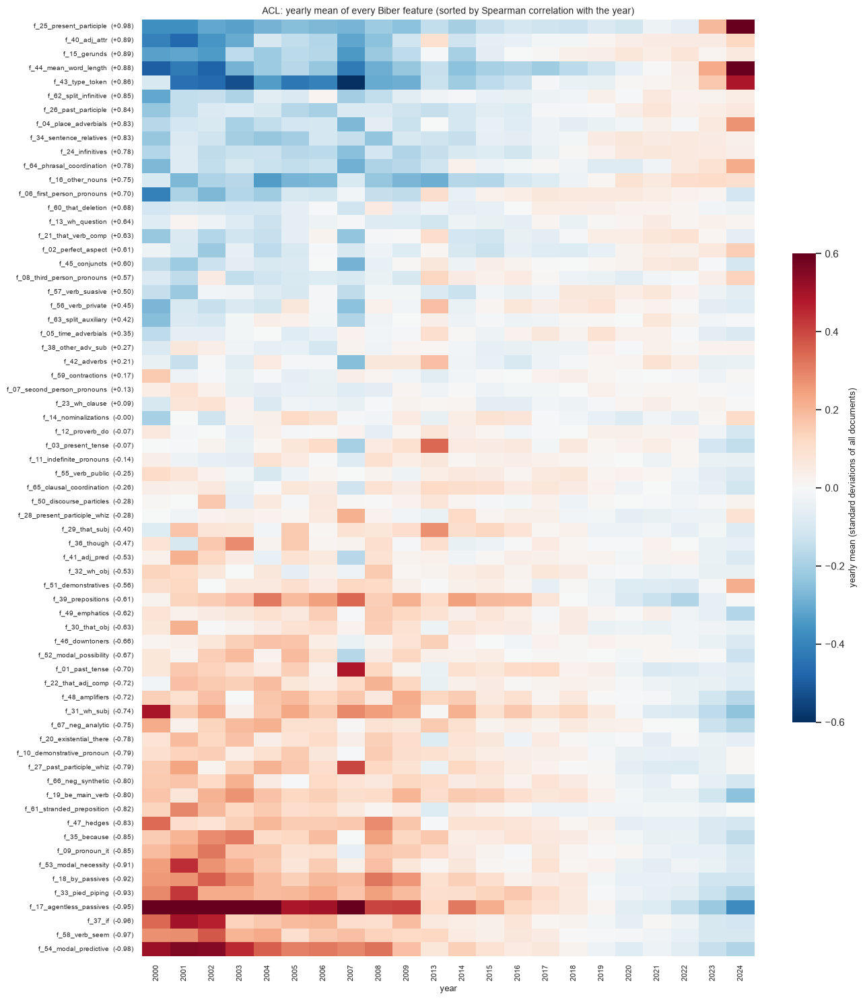

In [11]:
RESULTS = ROOT / "outputs/acl/results"
acl_docs = pd.read_parquet(ROOT / "outputs/acl/corpus/corpus.parquet", columns=["year", "venue_tier"])
acl_features = pd.read_parquet(ROOT / "outputs/acl/features/biber_features.parquet")
common = acl_docs.index.intersection(acl_features.index)
acl_docs, acl_features = acl_docs.loc[common], acl_features.loc[common]
scaler = pd.read_csv(RESULTS / "reference_scaler.csv", index_col=0)
acl_z = (acl_features[scaler.index] - scaler["mean"]) / scaler["std"]
acl_years = acl_docs["year"].astype(int)
ACL_YEARS = acl_years.value_counts().loc[lambda s: s >= 100].index.sort_values()
acl_yearly = yearly_z(acl_z, acl_years, ACL_YEARS)
print(f"{len(acl_z):,} papers x {acl_z.shape[1]} features; years shown: {', '.join(map(str, ACL_YEARS))}")
trend_heatmap(acl_yearly, "ACL: yearly mean of every Biber feature (sorted by Spearman correlation with the year)")
plt.show()

<!-- obs:acl_heatmap -->
**What we see:**
- An almost perfect gradient: most features trend monotonically over 25 years.
  - **Rising** (blue in the 2000s, red in 2024): present participles, attributive adjectives, gerunds, word
    length, type-token ratio (Spearman ρ ≥ 0.86).
  - **Falling**: predictive and necessity modals, agentless and *by*-passives, *if*, pied-piping,
    *seem/appear* (ρ ≤ −0.9).
- The two most extreme columns are **2024** (strongest shift) and **2007** (the workshop-heavy year).

,change per decade (sd),Spearman rho with year,direction
f_43_type_token,0.288,0.858,rising
f_44_mean_word_length,0.251,0.885,rising
f_25_present_participle,0.227,0.981,rising
f_40_adj_attr,0.195,0.892,rising
f_15_gerunds,0.170,0.889,rising
f_16_other_nouns,0.147,0.750,rising
f_06_first_person_pronouns,0.131,0.703,rising
f_64_phrasal_coordination,0.115,0.779,rising
f_17_agentless_passives,-0.403,-0.954,falling
f_54_modal_predictive,-0.284,-0.979,falling


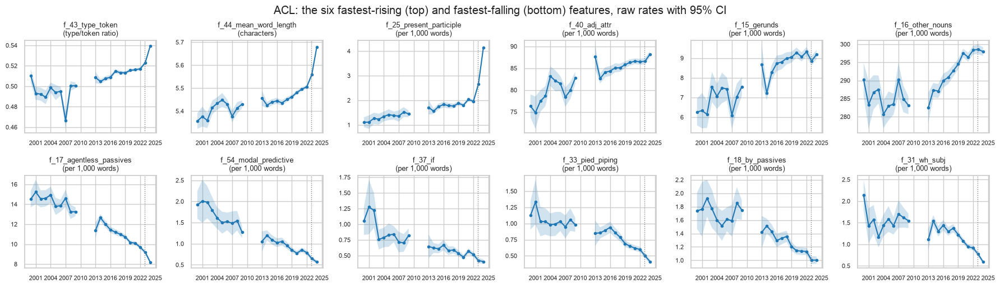

In [12]:
table = trend_table(acl_yearly).sort_values("change per decade (sd)")
display(pd.concat([table.tail(8)[::-1].assign(direction="rising"), table.head(8).assign(direction="falling")]).round(3))
top = list(table.tail(6).index[::-1]) + list(table.head(6).index)
mean, half = mean_ci(acl_features.loc[acl_years.isin(ACL_YEARS), top], acl_years[acl_years.isin(ACL_YEARS)])
line_panels(full_range(mean), full_range(half), top, [f"{f}\n({feature_unit(f)})" for f in top], ncols=6, panel=(3.0, 2.5))
plt.suptitle("ACL: the six fastest-rising (top) and fastest-falling (bottom) features, raw rates with 95% CI", y=1.02)
plt.show()

<!-- obs:acl_top_features -->
**What we see:**
- **Rising**: type-token ratio 0.51 → 0.54, word length 5.36 → 5.68 characters, **present participles
  1.1 → 4.1 per 1,000 words (most of it in 2023–24)**, attributive adjectives 76 → 88, gerunds 6.3 → 9.2,
  nouns ~285 → 298.
- **Falling**: agentless passives 14.6 → 8.2, predictive modals 2.0 → 0.6, *if* 1.1 → 0.4, pied-piping
  1.1 → 0.4, *by*-passives 1.8 → 1.0, *wh*-relatives 2.1 → 0.6.
- Two kinds of change: **slow 25-year trends** (passives, modals, nouns) and a **sudden 2023–24 jump**
  (participles, word length, type-token ratio).

### Feature change between the key years: absolute, relative and combined
From the pipeline's `feature_change` analysis (`outputs/acl/results/feature_change/all/`). For each step
between the key years (2000 → 2019 → 2024) and the full span, the **top 10 features** are ranked three ways:

1. **Absolutely**: the difference of the yearly means, in the feature's own unit (per 1,000 words, except
   the type-token ratio and the word length). This favours frequent features (nouns, prepositions, tenses).
2. **Relatively**: the difference as a percentage of the earlier mean. This favours rare features.
3. **Combined**: both magnitudes min-max scaled to 0–1 across all features and averaged (0.5 each), as in
   the original AO3 notebook. A feature ranks high only if it changes a lot in both senses.

Bar colour gives the direction (blue: the mean increased, orange: it decreased).

#### ACL: 2000 → 2019

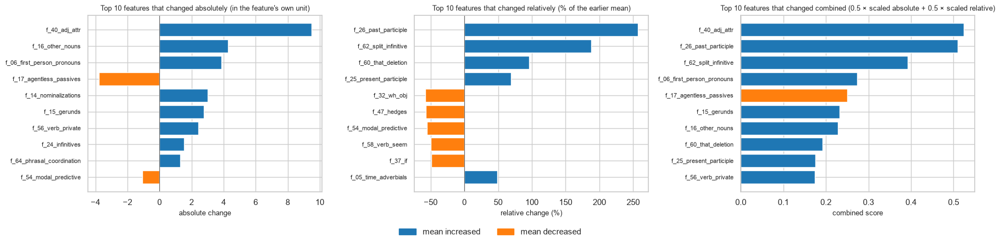

,absolutely,relatively,combined
rank,,,
1,f_40_adj_attr (+9.47),f_26_past_participle (+257%),f_40_adj_attr (0.52)
2,f_16_other_nouns (+4.27),f_62_split_infinitive (+188%),f_26_past_participle (0.51)
3,f_06_first_person_pronouns (+3.87),f_60_that_deletion (+96%),f_62_split_infinitive (0.39)
4,f_17_agentless_passives (-3.80),f_25_present_participle (+69%),f_06_first_person_pronouns (0.27)
5,f_14_nominalizations (+3.01),f_32_wh_obj (-58%),f_17_agentless_passives (0.25)
6,f_15_gerunds (+2.78),f_47_hedges (-57%),f_15_gerunds (0.23)
7,f_56_verb_private (+2.41),f_54_modal_predictive (-56%),f_16_other_nouns (0.23)
8,f_24_infinitives (+1.53),f_58_verb_seem (-49%),f_60_that_deletion (0.19)
9,f_64_phrasal_coordination (+1.30),f_37_if (-49%),f_25_present_participle (0.18)


#### ACL: 2019 → 2024

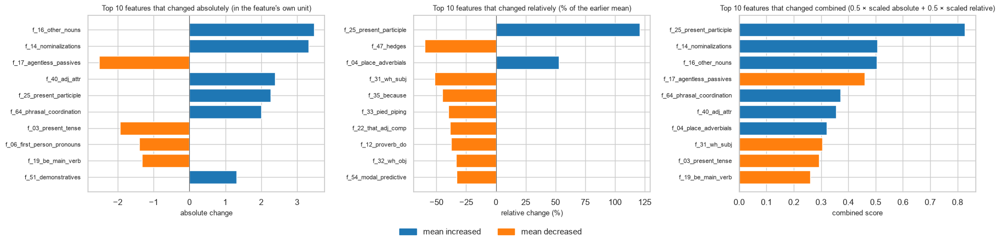

,absolutely,relatively,combined
rank,,,
1,f_16_other_nouns (+3.47),f_25_present_participle (+121%),f_25_present_participle (0.83)
2,f_14_nominalizations (+3.32),f_47_hedges (-60%),f_14_nominalizations (0.51)
3,f_17_agentless_passives (-2.52),f_04_place_adverbials (+53%),f_16_other_nouns (0.50)
4,f_40_adj_attr (+2.39),f_31_wh_subj (-52%),f_17_agentless_passives (0.46)
5,f_25_present_participle (+2.26),f_35_because (-45%),f_64_phrasal_coordination (0.37)
6,f_64_phrasal_coordination (+2.00),f_33_pied_piping (-40%),f_40_adj_attr (0.36)
7,f_03_present_tense (-1.94),f_22_that_adj_comp (-39%),f_04_place_adverbials (0.32)
8,f_06_first_person_pronouns (-1.40),f_12_proverb_do (-37%),f_31_wh_subj (0.30)
9,f_19_be_main_verb (-1.33),f_32_wh_obj (-33%),f_03_present_tense (0.29)


#### ACL: 2000 → 2024

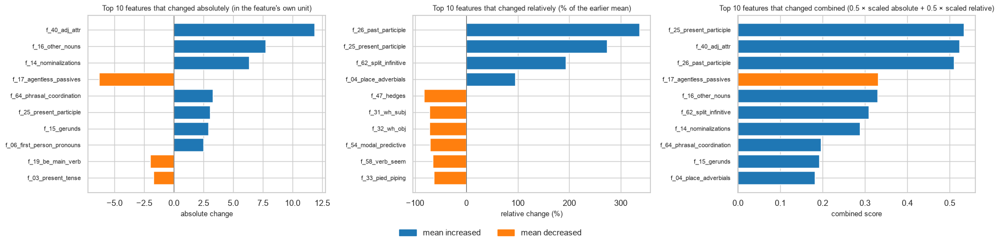

,absolutely,relatively,combined
rank,,,
1,f_40_adj_attr (+11.87),f_26_past_participle (+337%),f_25_present_participle (0.53)
2,f_16_other_nouns (+7.75),f_25_present_participle (+274%),f_40_adj_attr (0.52)
3,f_14_nominalizations (+6.33),f_62_split_infinitive (+193%),f_26_past_participle (0.51)
4,f_17_agentless_passives (-6.32),f_04_place_adverbials (+94%),f_17_agentless_passives (0.33)
5,f_64_phrasal_coordination (+3.30),f_47_hedges (-83%),f_16_other_nouns (0.33)
6,f_25_present_participle (+3.03),f_31_wh_subj (-72%),f_62_split_infinitive (0.31)
7,f_15_gerunds (+2.91),f_32_wh_obj (-72%),f_14_nominalizations (0.29)
8,f_06_first_person_pronouns (+2.47),f_54_modal_predictive (-71%),f_64_phrasal_coordination (0.20)
9,f_19_be_main_verb (-2.01),f_58_verb_seem (-66%),f_15_gerunds (0.19)


In [13]:
show_feature_change(ROOT / "outputs/acl", "ACL")

<!-- obs:acl_feature_change -->
**What we see:**
- **The three rankings answer different questions.**
  - **Absolute** change is led by frequent features: attributive adjectives (+11.9 per 1,000 words from
    2000 to 2024), nouns (+7.8), nominalizations (+6.3) and agentless passives (−6.3).
  - **Relative** change is led by rare features that start from a tiny base: past-participle clauses
    (+337%, from 0.08 to 0.33 per 1,000 words) and split infinitives (+193%). Read these with care.
  - The **combined** score keeps the features that change a lot in both senses.
- **2000 → 2019** (the slow trend): attributive adjectives, past participles, split infinitives,
  first-person pronouns and agentless passives lead the combined ranking. Modals, hedges, *seem* and
  *wh*-relatives fall by about half in relative terms.
- **2019 → 2024** (the recent jump): **present participial clauses top the combined ranking with a wide
  lead (0.83 against 0.51 for the next feature)** and are the only feature near the top of all three lists
  (+2.3 per 1,000 words, +121%). They are followed by nominalizations, nouns and agentless passives.
- Over the full span (2000 → 2024), the combined top five are present participles, attributive
  adjectives, past participles, agentless passives and nouns.

## 1.5 Biber's seven dimensions across the years
Dimension scores per paper (Biber 1988 loadings, standardised against Biber's 1988 norms, as in the
paper), averaged per year with 95% CI.

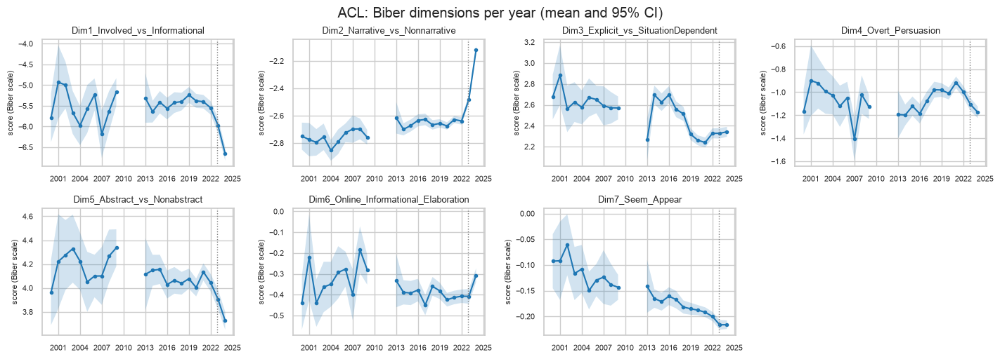

In [14]:
acl_dims = BiberDimensionScorer("biber1988", include_seem_appear=True).score(acl_features)
keep = acl_years.isin(ACL_YEARS)
mean, half = mean_ci(acl_dims[keep], acl_years[keep])
line_panels(full_range(mean), full_range(half), list(acl_dims.columns), ncols=4, ylabel="score (Biber scale)")
plt.suptitle("ACL: Biber dimensions per year (mean and 95% CI)", y=1.02)
plt.show()

<!-- obs:acl_dimensions -->
**What we see:**
- **Dimension 1** drops in 2023–24 (−5.6 → −6.7): papers become even more "informational".
- **Dimension 2** jumps (−2.6 → −2.1), because present participles load on it.
- **Dimension 5** (abstract style) falls from 4.1 (2021) to 3.7 (2024) with the decline of passives.
- Dimension 3 falls in 2016–2020; Dimension 4 rises in 2014–2021 and then falls; Dimension 7 declines
  steadily.

## 1.6 How similar are the years to each other?
The pipeline's pairwise MMD² between fixed samples of 250 papers per year (`results/mmd_by_year_*.csv`),
shown three ways: the full matrix, the change from each year to the next, and a 2-D "map" in which
years that are stylistically close sit close together.

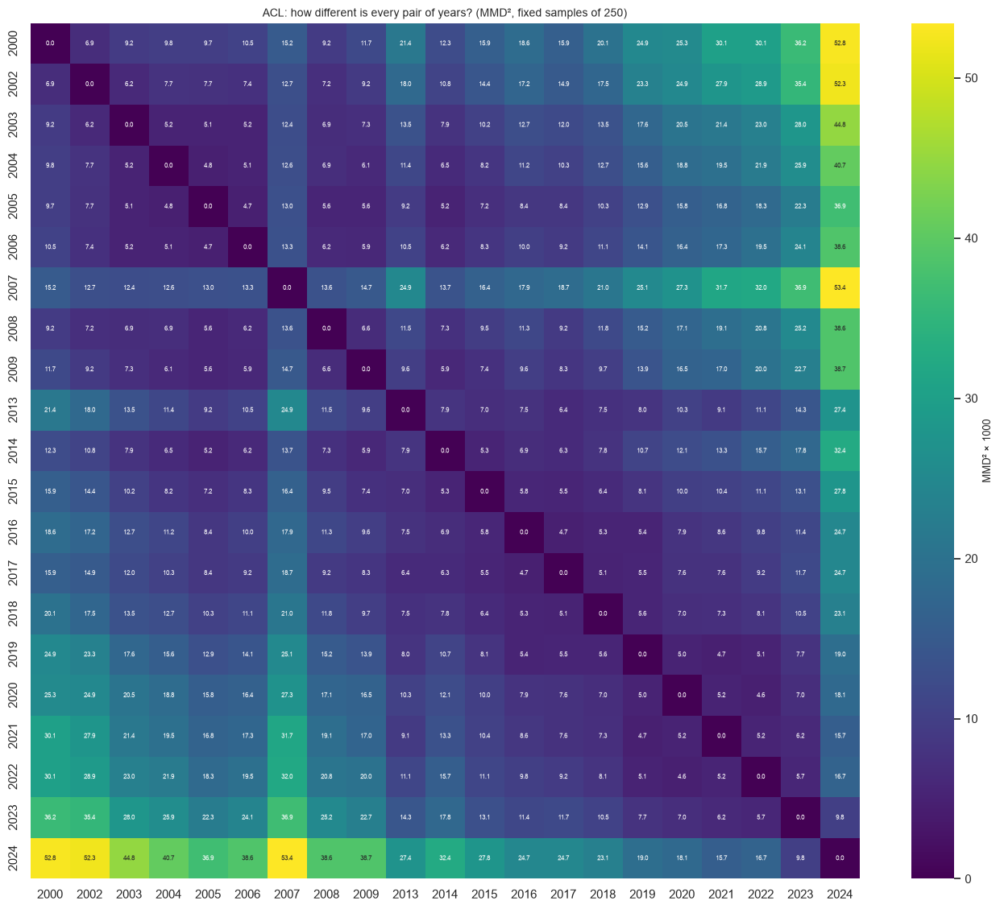

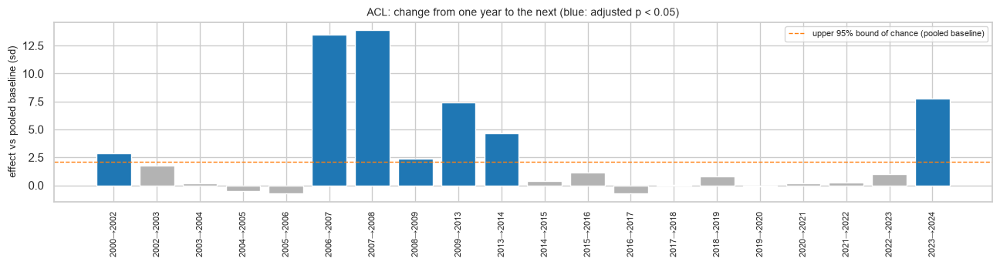

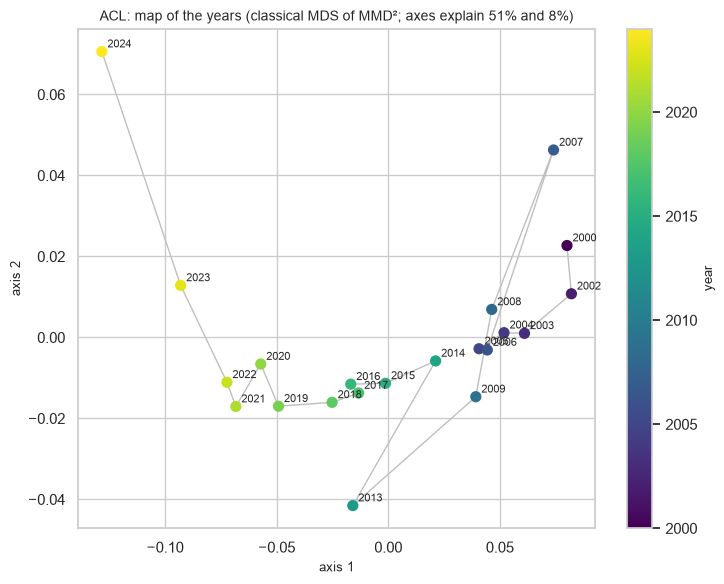

In [15]:
acl_matrix, acl_steps = mmd_figures(RESULTS, "ACL")

<!-- obs:acl_mmd -->
**What we see:**
- **Distance grows with the time gap**: the 2000s are far from the 2020s, and **2024 is far from every other
  year**, including 2023 (MMD² 9.8 × 10⁻³ against ~5 for neighbouring years in 2019–2022).
- **Year-to-year steps**: every step from 2014 to 2023 is at chance level (−0.7 to 1.1). The large steps are
  2006 → 2007 → 2008 (the 2007 outlier), 2009 → 2013 (data gap), 2013 → 2014, and **2023 → 2024 (7.8)**.
- The map of years is a **path**: the 2000s on the right, then 2013 → 2022 moving steadily left, then 2023
  and 2024 jumping away. Axis 1 (51% of the structure) is essentially time.

## 1.7 The style space: where does each year sit?
A principal component analysis of all papers' standardised features; each point is the average
paper of a year.

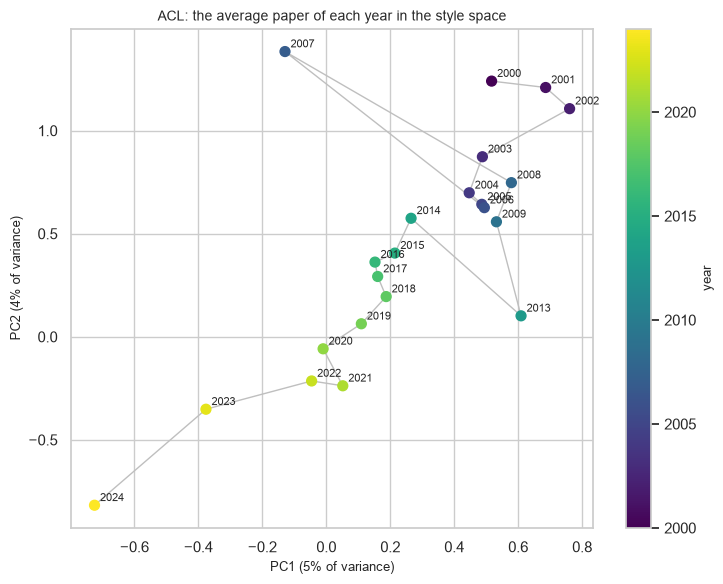

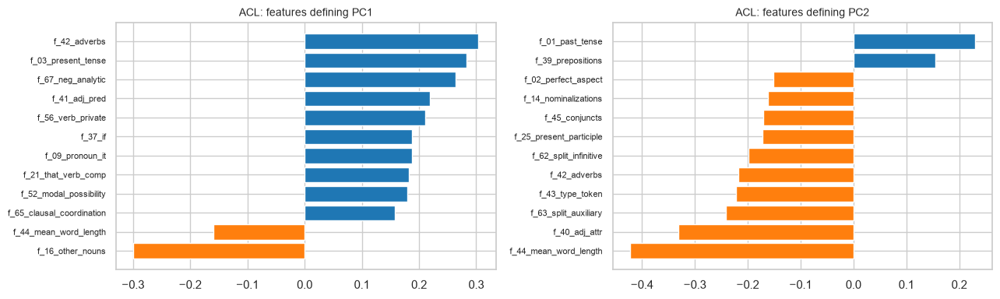

In [16]:
scores, loadings, explained = pca(acl_z)
centroids = scores[acl_years.isin(ACL_YEARS)].groupby(acl_years).mean().loc[ACL_YEARS]
plot_trajectory(centroids.to_numpy(), list(ACL_YEARS), "ACL: the average paper of each year in the style space",
                f"PC1 ({explained[0]:.0%} of variance)", f"PC2 ({explained[1]:.0%} of variance)")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    top_loadings = loadings[pc].reindex(loadings[pc].abs().nlargest(12).index).sort_values()
    ax.barh(top_loadings.index, top_loadings.values, color=np.where(top_loadings.values > 0, "tab:blue", "tab:orange"))
    ax.set_title(f"ACL: features defining {pc}")
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()

<!-- obs:acl_pca -->
**What we see:**
- The average paper moves along a diagonal from the 2000s (upper right) to 2024 (lower left): steadily from
  2014 to 2022, then in two big steps (2023, 2024).
- **PC1** contrasts "involved" features (adverbs, present tense, negation, private verbs) with nouns and
  word length; **PC2** contrasts past tense and prepositions with word length, attributive adjectives and
  type-token ratio.
- Each component explains only 4–5% of the variation between single documents (documents are noisy), but
  the year averages separate clearly.

## 1.8 Diversity: are the papers of a year becoming more alike?
Two pipeline outputs: the total variance of the standardised features per year (`variance.csv`) and
the MMD² between two random halves of the same year (`mmd_by_year_baselines.csv`; only years with at
least 500 papers). Lower values mean more uniform papers.

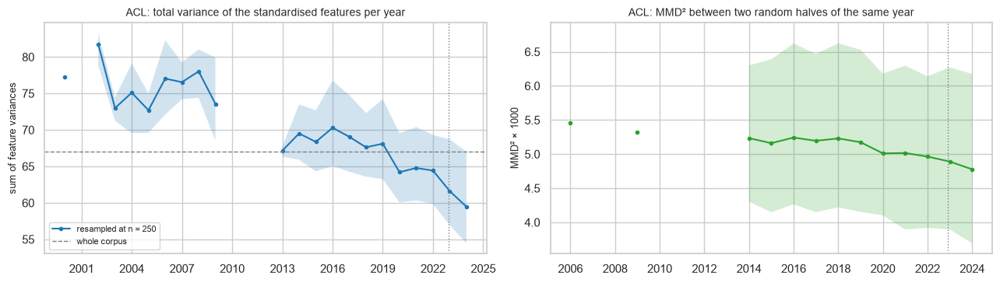

In [17]:
diversity_figure(RESULTS, "ACL")

<!-- obs:acl_diversity -->
**What we see:**
- **Papers are becoming more alike**: total variance falls from ~73–82 (2000s) to ~68–70 (2014–2019) and
  **59.5 (2024)**, the steepest fall after 2019. Intervals are wide (resampled at 250 papers).
- The within-year MMD² agrees: from 5.2 to 4.8 × 10⁻³.

## 1.9 Venue tiers: do A*, conference and workshop papers move together?

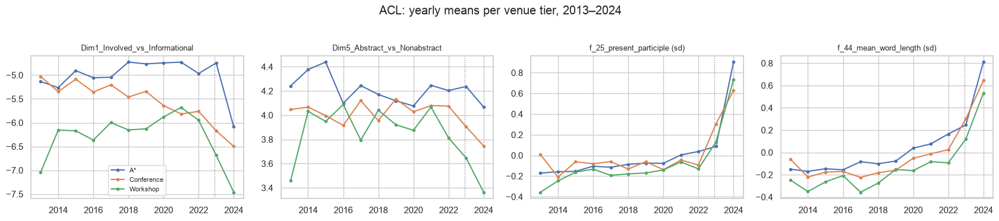

In [18]:
recent = acl_years.between(2013, 2024)
tier = acl_docs.loc[recent, "venue_tier"]
values = pd.concat([acl_dims.loc[recent, ["Dim1_Involved_vs_Informational", "Dim5_Abstract_vs_Nonabstract"]],
                    acl_z.loc[recent, ["f_25_present_participle", "f_44_mean_word_length"]]], axis=1)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, column in zip(axes, values.columns):
    for name, group in values[column].groupby(tier):
        series = group.groupby(acl_years[group.index]).mean()
        ax.plot(series.index, series.values, "-o", ms=3, label=name)
    ax.axvline(BREAK, color="0.5", ls=":", lw=1)
    int_years(ax)
    ax.set_title(column + ("" if column.startswith("Dim") else " (sd)"), fontsize=9)
axes[0].legend(fontsize=8)
fig.suptitle("ACL: yearly means per venue tier, 2013–2024", y=1.03)
fig.tight_layout()
plt.show()

<!-- obs:acl_tiers -->
**What we see:**
- **All three tiers move together**: the 2023–24 jump in present participles and word length appears in
  A*, conference and workshop papers alike.
- Tiers differ in level: A* papers are the most "involved" (highest Dimension 1) and the most abstract
  (Dimension 5); workshop papers the most informational.

## 1.10 Figures from the pipeline (`outputs/acl/figures`)
The figures the pipeline's `report` stage already drew for ACL, grouped by topic.

### Corpus and quality

`documents_by_year.png`: Documents per year after cleaning and the 400-word window.

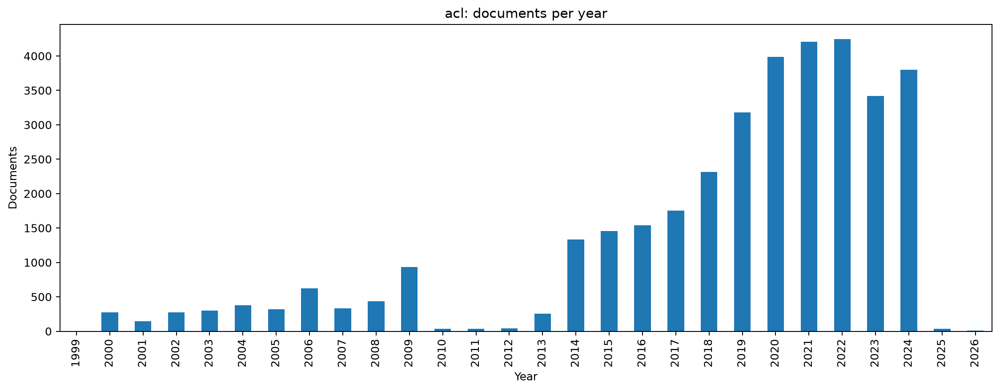

`quality_metrics.png`: Distribution of the seven malformed-text metrics (dashed line: flag threshold).

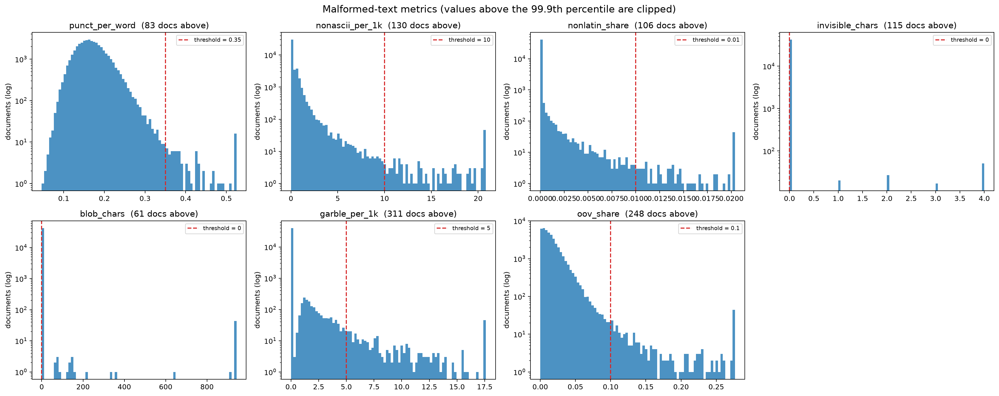

`quality_flags_by_year.png`: Share of documents carrying each quality flag, per year.

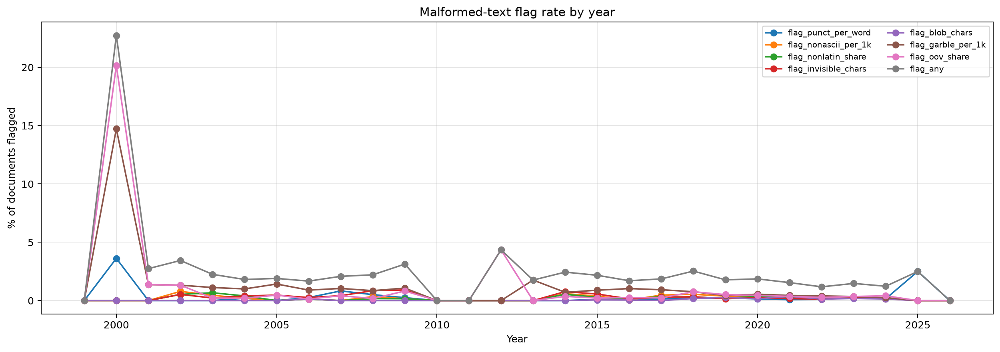

### How different are the years? (MMD²)

`mmd_by_year_heatmap.png`: Pairwise MMD² between the years (fixed samples per year).

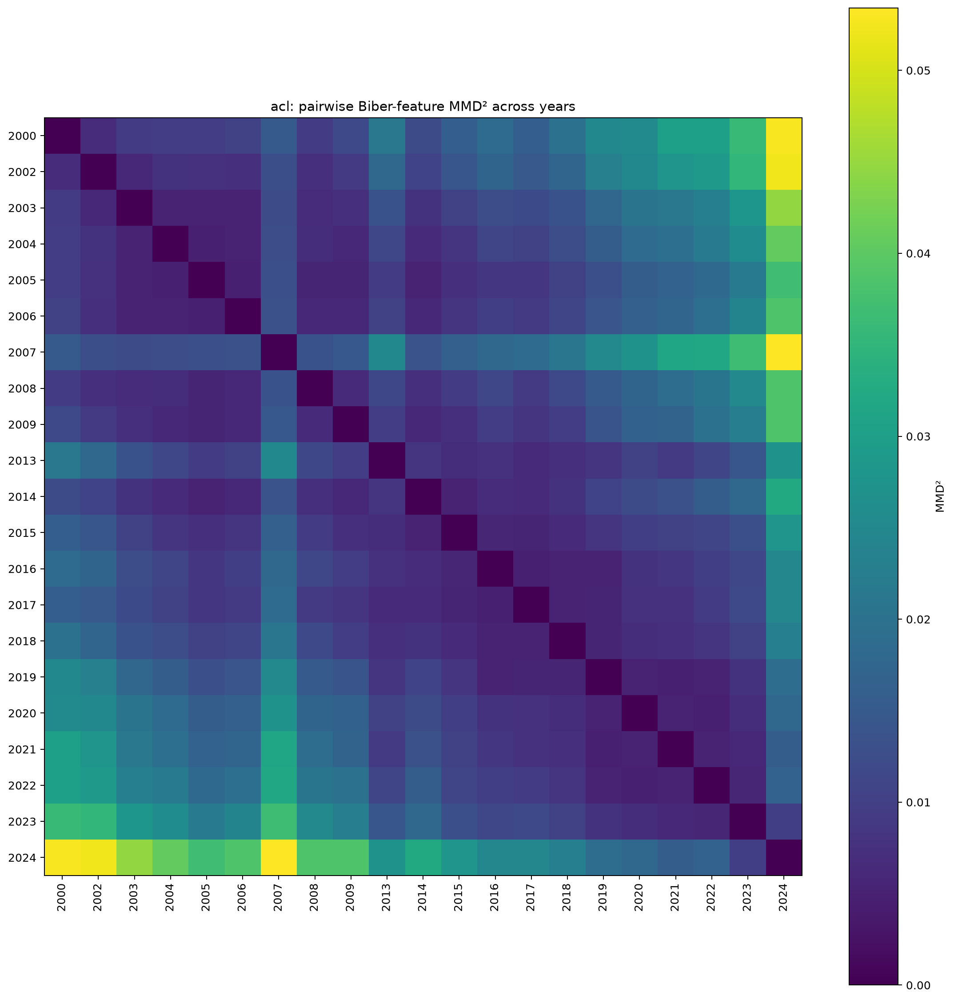

`mmd_by_era_group_heatmap.png`: Pairwise MMD² between era × venue-tier cohorts (fixed samples of 50).

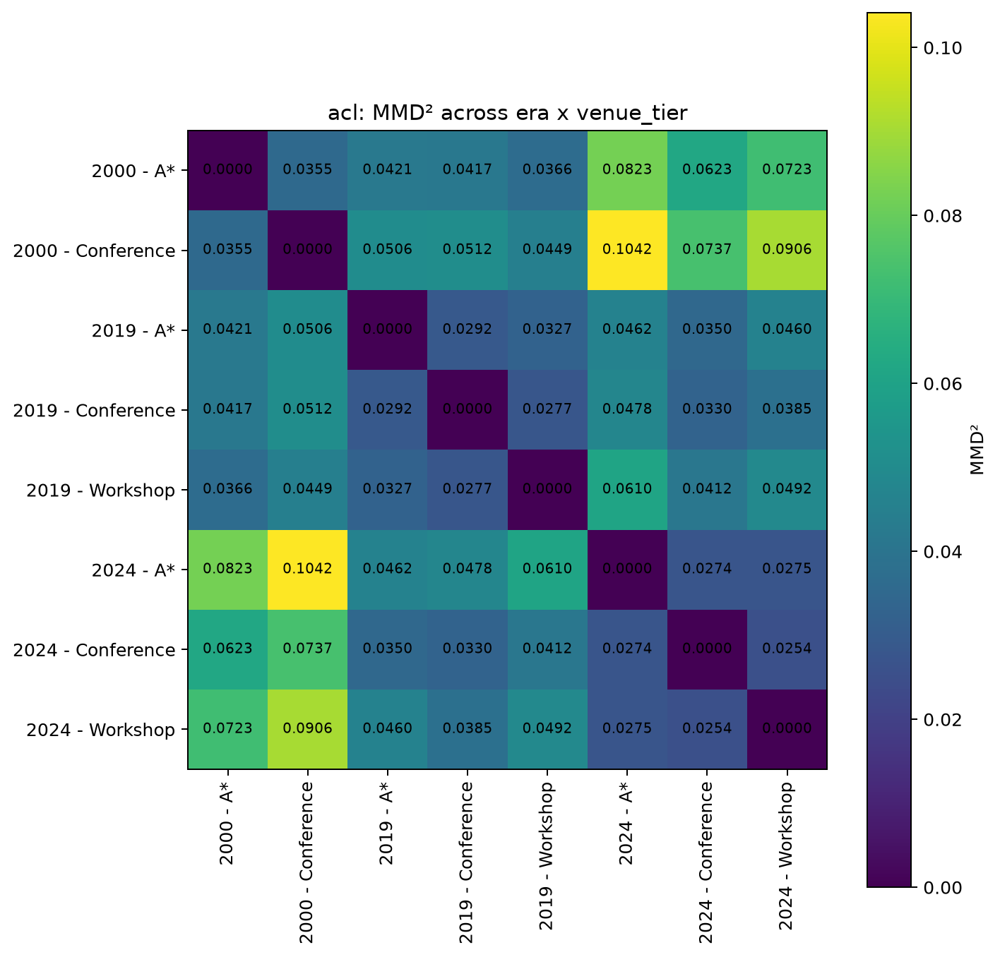

### Sample-size stability (choosing n)

`sample_size_stability_era.png`: The same per era.

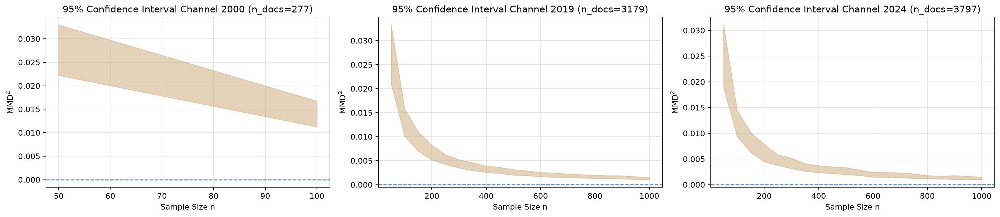

`sample_size_stability_group.png`: The same per venue tier.

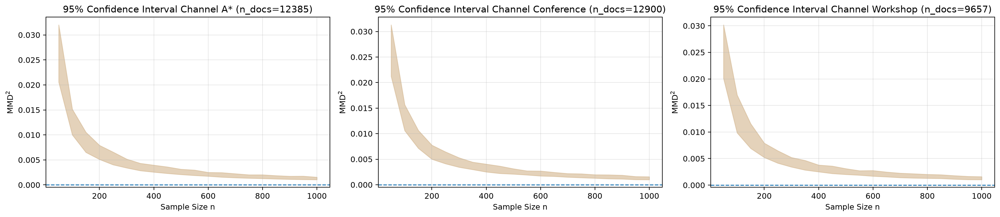

`sample_size_stability_era_group.png`: The same per era × venue tier.

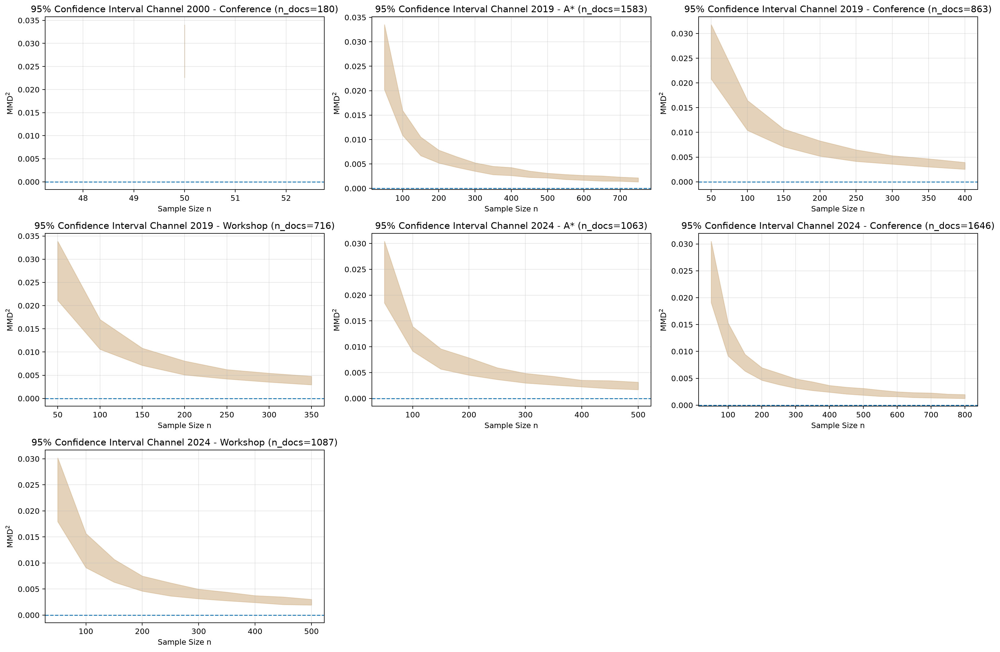

### Biber dimensions

`biber_dimensions_by_era.png`: Dimension scores per era (violins).

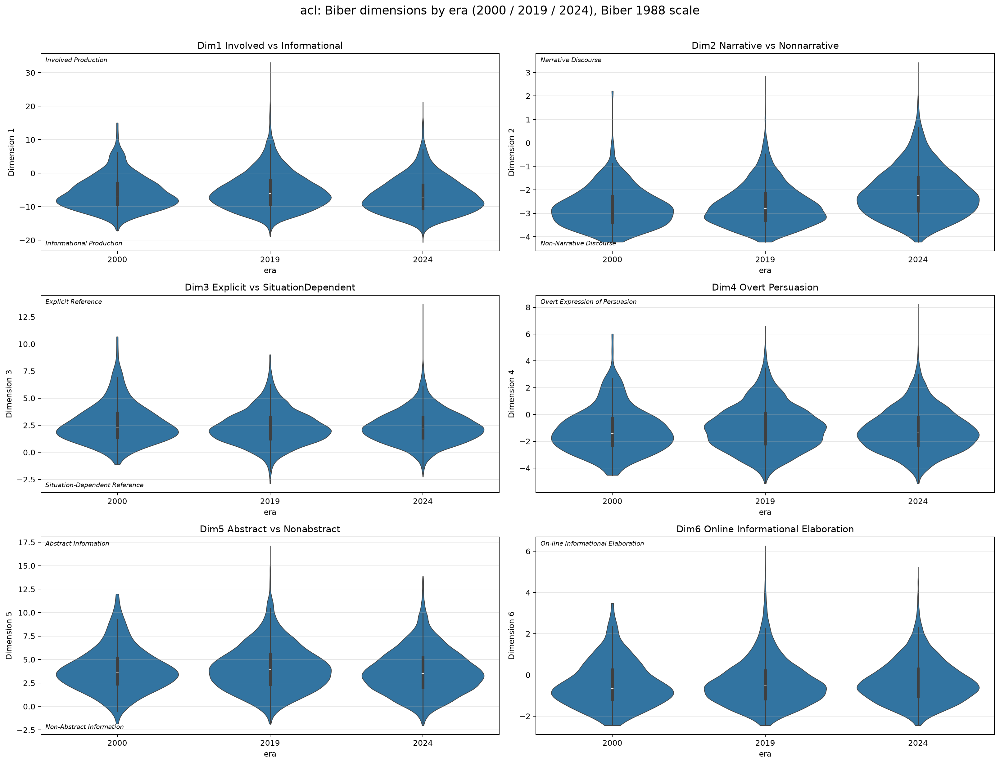

`biber_dimensions_by_group.png`: Dimension scores per venue tier.

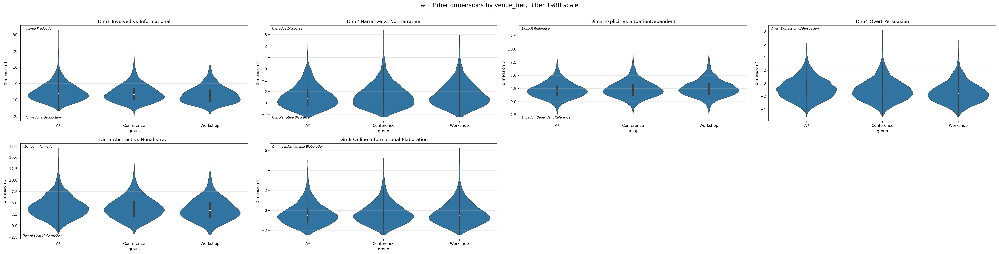

`biber_dimensions_by_era_group.png`: Dimension scores per era and venue tier.

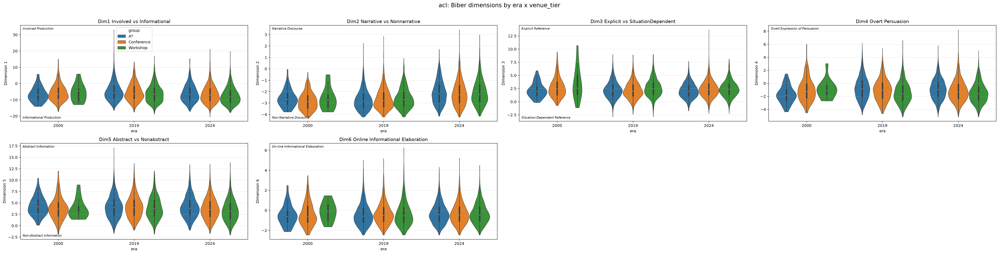

### Feature shifts

`feature_shifts_2000_2019_2024.png`: Largest per-feature shifts (Wasserstein distance) for each key-year step and the full span.

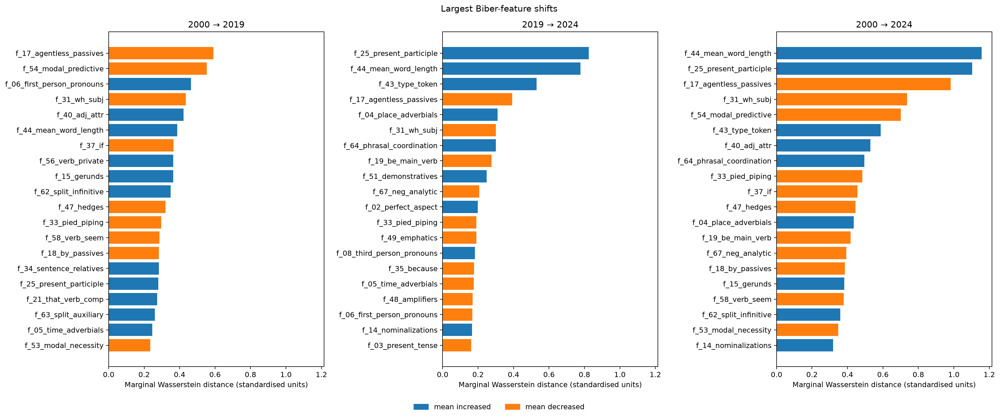

`feature_shifts_2000_2024.png`: Older version of this figure (first vs last year only), left over from an earlier pipeline run.

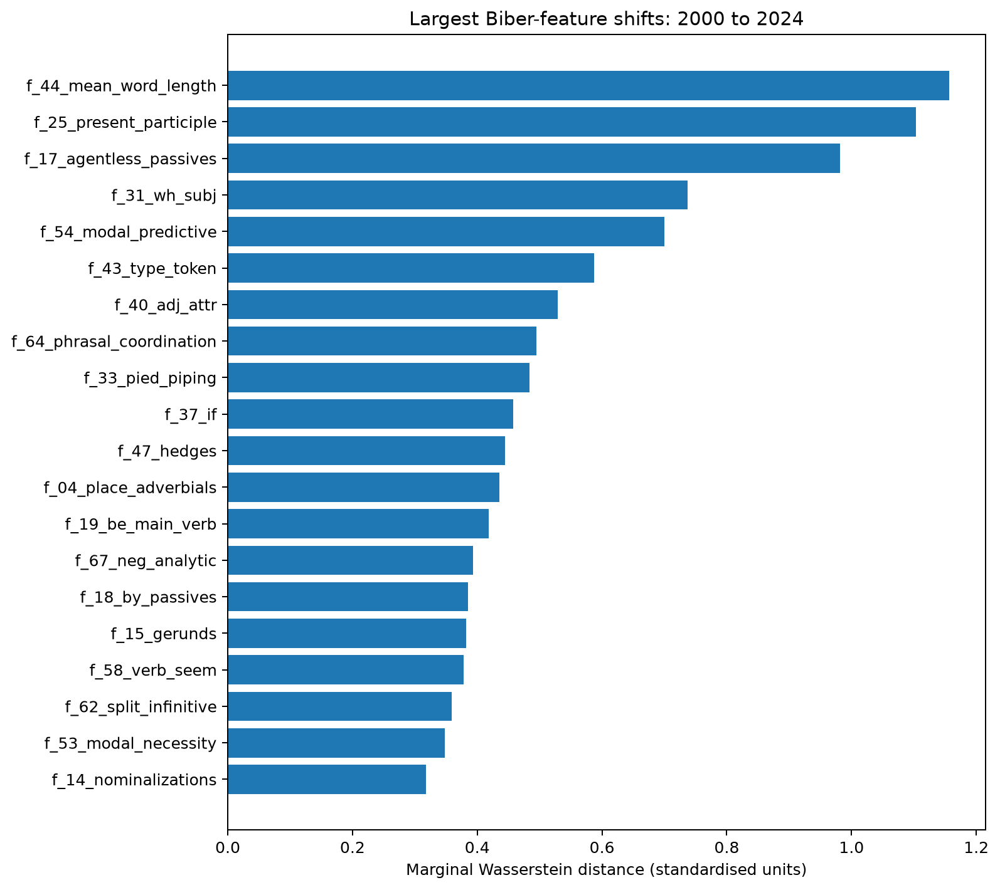

### Diversity

`variance_by_year.png`: Total variance of the standardised features per year.

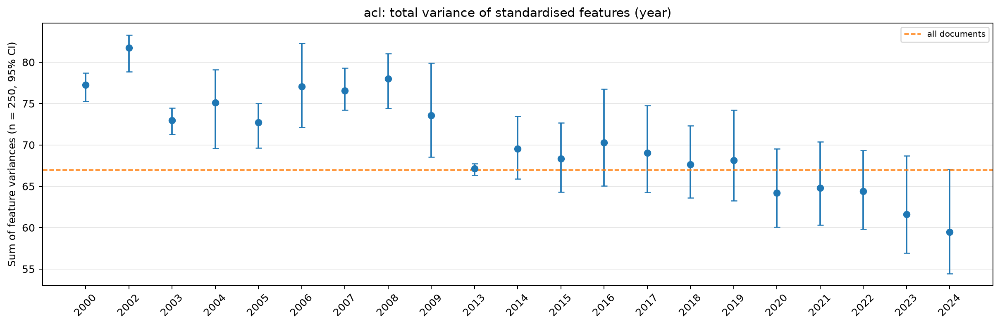

`variance_by_era_group.png`: Total variance per era × venue tier.

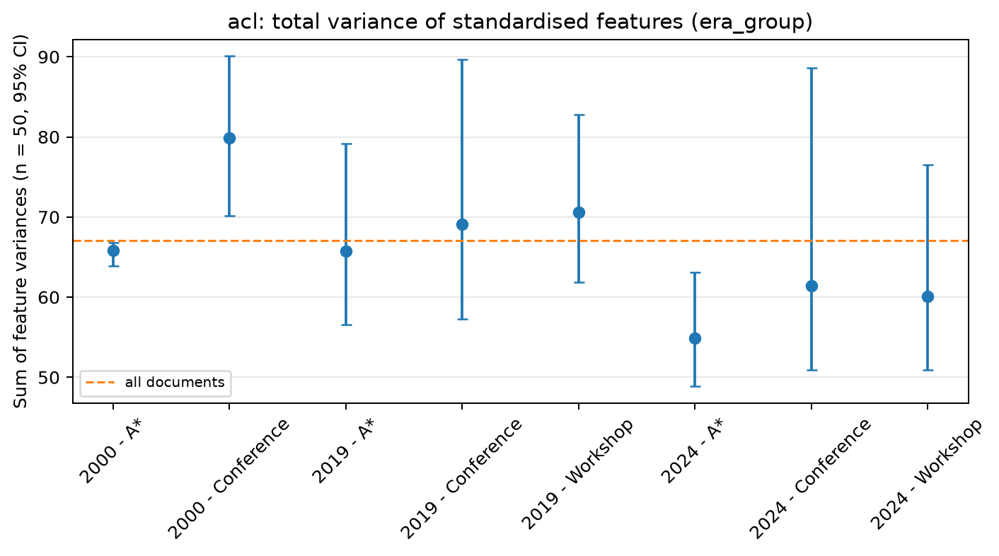

### Interrupted time series

`trend_level_changes.png`: Largest jumps at the break beyond the pre-break trend (features).

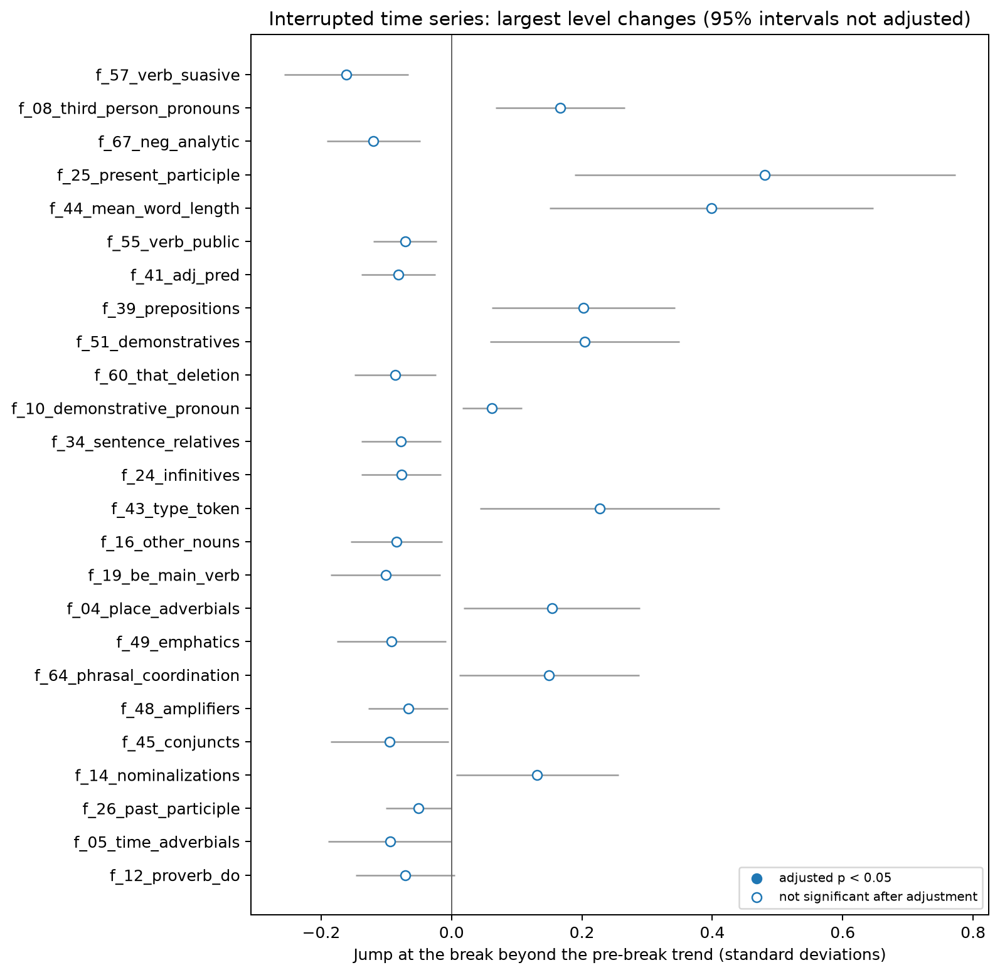

`trend_series_dimensions.png`: Total variance and the seven dimensions with the fitted segmented trend.

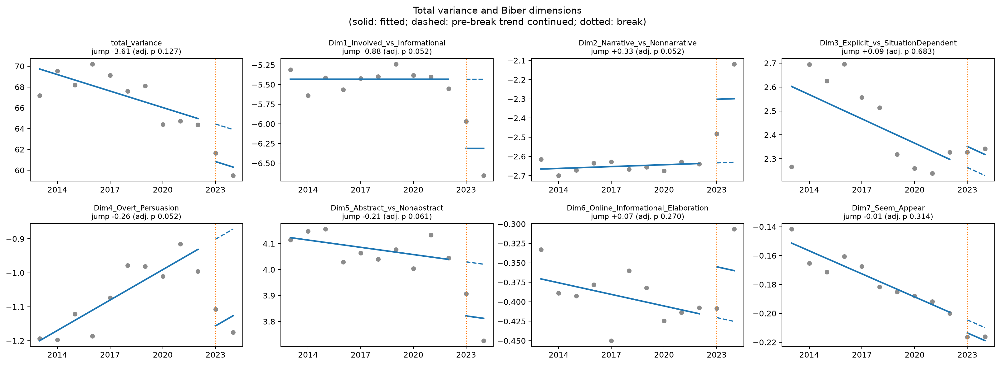

`trend_series_features.png`: The eight features that departed most from their pre-break trend.

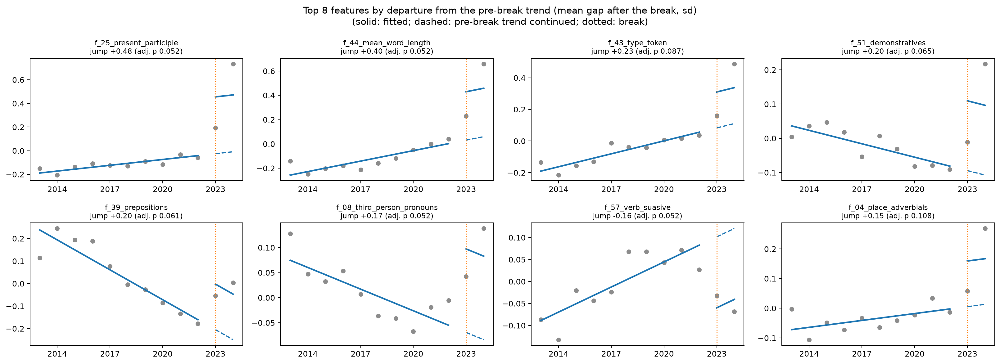

In [19]:
show_pipeline_figures(ROOT / "outputs/acl/figures")

---
# Part 2: AO3 fan fiction

## 2.1 What the raw data looks like
`data/raw/ao3/`: four CSV files, one per fandom tag, one row per posted chapter. Only the metadata
columns are read (the story text is skipped).

In [20]:
AO3_DIR = ROOT / "data/raw/ao3"
FANDOM_OF_FILE = {"legendarium": "Middle-earth legendarium (umbrella tag)", "hobbit": "The Hobbit",
                  "lord_of_the_rings": "The Lord of the Rings", "silmarillion": "The Silmarillion"}
frames, files = [], []
for path in sorted(AO3_DIR.glob("*chapters_with_text.csv")):
    header = pd.read_csv(path, nrows=0).columns
    frame = pd.read_csv(path, usecols=[c for c in header if c != "story_text"], dtype=str)
    frame = frame.rename(columns={"liststatus": "status", "ing_date": "listing_date"})  # one file's header is mangled
    frame["file"] = next(v for k, v in FANDOM_OF_FILE.items() if k in path.name)
    frames.append(frame)
    files.append({"file": frame["file"].iloc[0], "chapters": len(frame), "works": frame["work_id"].nunique(),
                  "header problem": "liststatus / ing_date" if "liststatus" in header else ""})
ao3_all = pd.concat(frames, ignore_index=True)
display(pd.DataFrame(files).set_index("file"))
in_files = ao3_all.groupby("chapter_id")["file"].nunique()
print(f"{len(ao3_all):,} rows; {in_files.size:,} distinct chapters; {int((in_files > 1).sum()):,} chapters appear in "
      f"more than one fandom file (crossovers)")

,chapters,works,header problem
file,,,
Middle-earth legendarium (umbrella tag),48645,15090,liststatus / ing_date
The Hobbit,48171,9775,
The Lord of the Rings,107382,19858,
The Silmarillion,44616,14655,


248,814 rows; 163,912 distinct chapters; 46,434 chapters appear in more than one fandom file (crossovers)


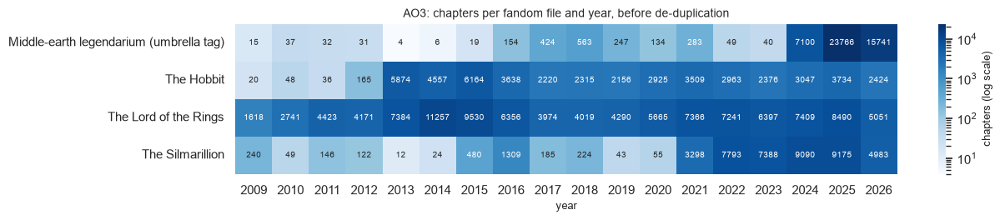

In [21]:
coverage = pd.crosstab(pd.to_datetime(ao3_all["chapter_date"], errors="coerce").dt.year, ao3_all["file"]).loc[2009:2026]
fig, ax = plt.subplots(figsize=(13, 2.8))
sns.heatmap(coverage.T.replace(0, np.nan), annot=coverage.T, fmt="d", annot_kws={"size": 7}, cmap="Blues", norm=LogNorm(), ax=ax,
            cbar_kws={"label": "chapters (log scale)"})
ax.set_title("AO3: chapters per fandom file and year, before de-duplication")
ax.set_xlabel("year")
ax.set_ylabel("")
fig.tight_layout()
plt.show()

<!-- obs:ao3_coverage -->
**What we see:**
- 248,814 rows hold **163,912 distinct chapters**; 46,434 chapters appear in more than one fandom file
  (crossovers) and are kept once.
- **Important: coverage changes over time.** AO3 lists works newest first, and two scrapes stopped early
  (no `.done` marker; their checkpoints are at pages 1071 and 1068):
  - **The Silmarillion file only covers works created since early 2021.** Its older chapters are mostly
    backdated archive imports (e.g. `OEAM_Archivist`).
  - **The umbrella "legendarium" file only covers works created since September 2024**, but then contains
    almost everything (23,766 chapter rows in 2025). It sorts first, so after de-duplication 92–96% of the
    2025–26 chapters are credited to it.
  - **The Hobbit and Lord of the Rings scrapes are complete** (2009–2026).
- So Silmarillion-only works before 2021 are missing. Comparisons across 2021 mix in a coverage change.
  Resuming the two scrapes from their checkpoints would fix it.

In [22]:
ao3 = ao3_all.drop_duplicates("chapter_id").copy()
ao3["chapter_date"] = pd.to_datetime(ao3["chapter_date"], errors="coerce")
ao3 = ao3[ao3["chapter_date"].dt.year.between(2009, 2026)].copy()
ao3["year"] = ao3["chapter_date"].dt.year
NUMERIC = ["chapter_number", "chapter_word_count", "word_count", "chapters_posted", "chapters_expected",
           "comments", "kudos", "bookmarks", "hits"]
for column in NUMERIC:
    ao3[column] = pd.to_numeric(ao3[column], errors="coerce")
IDENTIFYING = {"title", "authors", "chapter_title", "relationships", "characters", "additional_tags", "freeform_tags"}
rows = []
for column in [c for c in ao3.columns if c not in {"file", "year"}]:
    values = ao3[column]
    filled = values.notna() & values.astype(str).str.strip().ne("")
    example = "(names / free text, not shown)" if column in IDENTIFYING else str(values.dropna().iloc[0])[:50]
    rows.append({"column": column, "filled (%)": round(100 * filled.mean(), 1), "example": example})
print(f"{len(ao3):,} distinct chapters dated 2009–2026")
display(pd.DataFrame(rows).set_index("column"))

163,912 distinct chapters dated 2009–2026


,filled (%),example
column,,
work_id,100.0,91982661
chapter_id,100.0,245022221
chapter_number,100.0,1
chapter_title,100.0,"(names / free text, not shown)"
chapter_date,100.0,2026-09-04 00:00:00
chapter_word_count,99.7,1430.0
title,100.0,"(names / free text, not shown)"
authors,100.0,"(names / free text, not shown)"
fandoms,100.0,The Silmarillion and other histories of Middle-Ear


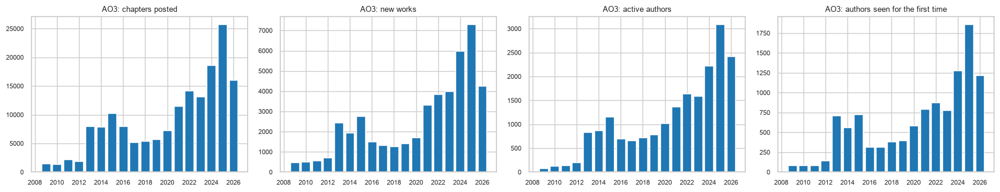

45,362 works by 11,193 named authors (Anonymous / orphan_account excluded)


In [23]:
works = (ao3.sort_values("chapter_number").drop_duplicates("work_id").set_index("work_id")
         .drop(columns=["chapter_id", "chapter_number", "chapter_title", "chapter_word_count", "chapter_date"]))
works["start"] = ao3.groupby("work_id")["chapter_date"].min()
works["start_year"] = works["start"].dt.year
people = ao3[["year", "authors"]].assign(author=ao3["authors"].fillna("").str.split(";")).explode("author")
people["author"] = people["author"].str.strip()
people = people[~people["author"].str.lower().isin(["", "anonymous", "orphan_account"])]
first_seen = people.groupby("author")["year"].min()
activity = pd.DataFrame({
    "chapters posted": ao3.groupby("year").size(),
    "new works": works.groupby("start_year").size(),
    "active authors": people.groupby("year")["author"].nunique(),
    "authors seen for the first time": first_seen.value_counts().sort_index(),
})
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, column in zip(axes, activity.columns):
    ax.bar(activity.index, activity[column], color="tab:blue")
    ax.set_title(f"AO3: {column}", fontsize=9)
    ax.tick_params(labelsize=8)
    int_years(ax)
fig.tight_layout()
plt.show()
print(f"{len(works):,} works by {people['author'].nunique():,} named authors (Anonymous / orphan_account excluded)")

<!-- obs:ao3_activity -->
**What we see:**
- **45,362 works by 11,193 named authors.** Fandom activity tracks the media: ~1,300–2,100 chapters a year
  in 2009–2012, a jump to ~8,000 in 2013 (the *Hobbit* films, 2012–14), a quieter 2017–2019 (~5,500), then
  growth to **25,800 chapters in 2025** (2026 counts only up to September).
- New authors spike in 2013 (~710) and rise again to **~1,860 in 2025**. The 2021 and late-2024 coverage
  changes inflate these counts too.

## 2.2 How the fan fiction itself changed (metadata)
Shares are per **work**, by the year of its first chapter, so long works do not dominate.

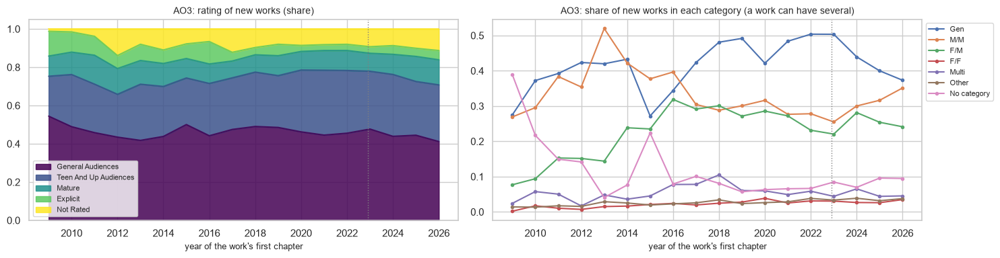

In [24]:
rating = pd.crosstab(works["start_year"], works["rating"].fillna("Not Rated"), normalize="index")
rating = rating[[c for c in ["General Audiences", "Teen And Up Audiences", "Mature", "Explicit", "Not Rated"] if c in rating]]
exploded = (works[["start_year"]].assign(category=works["category"].fillna("No category").str.split(", "))
            .explode("category").reset_index(drop=True))
category = pd.crosstab(exploded["start_year"], exploded["category"]).div(works.groupby("start_year").size(), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
rating.plot(kind="area", stacked=True, ax=axes[0], colormap="viridis", alpha=0.85)
axes[0].set_title("AO3: rating of new works (share)")
axes[0].legend(fontsize=8, loc="lower left")
for column in ["Gen", "M/M", "F/M", "F/F", "Multi", "Other", "No category"]:
    if column in category:
        axes[1].plot(category.index, category[column], "-o", ms=3, label=column)
axes[1].set_title("AO3: share of new works in each category (a work can have several)")
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
for ax in axes:
    ax.axvline(BREAK, color="0.5", ls=":", lw=1)
    ax.set_xlabel("year of the work's first chapter")
    int_years(ax)
fig.tight_layout()
plt.show()

<!-- obs:ao3_rating -->
**What we see:**
- **Ratings** shift slowly: General Audiences from 55% (2009) to 41% (2026), Teen And Up from ~20% to 30%,
  Not Rated from 1% to 11%. Explicit is low (5–13%) because works with sexual-content tags were excluded
  when scraping.
- **Categories** follow the fandom's waves: M/M peaks in 2013 (52%, *Hobbit* films), F/M grows from 8% (2009)
  to ~30% (2016), Gen peaks at 50% (2022–23) and falls to 37% (2026), while M/M rises again (26% → 35%).

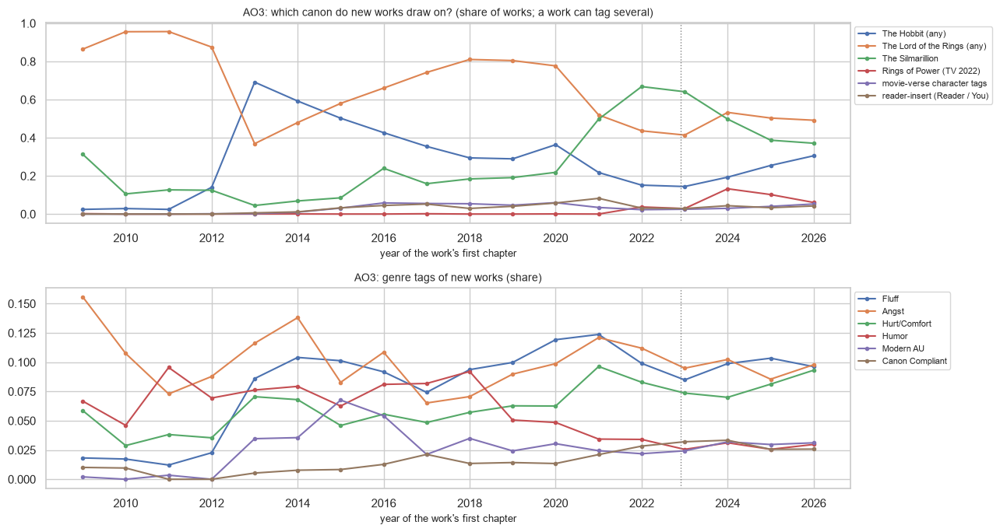

In [25]:
fandoms = works["fandoms"].fillna("")
tagtext = works["characters"].fillna("") + ";" + works["relationships"].fillna("")
source = pd.DataFrame({
    "The Hobbit (any)": fandoms.str.contains("Hobbit", case=False),
    "The Lord of the Rings (any)": fandoms.str.contains("Lord of the Rings", case=False),
    "The Silmarillion": fandoms.str.contains("Silmarillion", case=False),
    "Rings of Power (TV 2022)": fandoms.str.contains("Rings of Power", case=False) | tagtext.str.contains(r"Rings of Power|\(TV 2022\)", case=False, regex=True),
    "movie-verse character tags": tagtext.str.contains(r"Hobbit Movies|Lord of the Rings Movies|LotR Movies", case=False, regex=True),
    "reader-insert (Reader / You)": tagtext.str.contains(r"\bReader\b", regex=True),
}).groupby(works["start_year"]).mean()
tags = works["additional_tags"].fillna("").str.split(";").apply(lambda t: {x.strip() for x in t})
genre = pd.DataFrame({
    name: tags.apply(lambda t, names=names: bool(t & names))
    for name, names in {"Fluff": {"Fluff"}, "Angst": {"Angst"}, "Hurt/Comfort": {"Hurt/Comfort"}, "Humor": {"Humor"},
                        "Modern AU": {"Alternate Universe - Modern Setting"}, "Canon Compliant": {"Canon Compliant"}}.items()
}).groupby(works["start_year"]).mean()
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
source.plot(ax=axes[0], marker="o", ms=3)
axes[0].set_title("AO3: which canon do new works draw on? (share of works; a work can tag several)")
genre.plot(ax=axes[1], marker="o", ms=3)
axes[1].set_title("AO3: genre tags of new works (share)")
for ax in axes:
    ax.axvline(BREAK, color="0.5", ls=":", lw=1)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    ax.set_xlabel("year of the work's first chapter")
    int_years(ax)
fig.tight_layout()
plt.show()

<!-- obs:ao3_sources -->
**What we see:**
- **Canon shifts with the media**: The Lord of the Rings dominates until 2012 (86–96% of works). The Hobbit
  jumps to 69% in 2013 (the films), fades to 15% by 2022 and recovers to 31% in 2026. Rings of Power appears
  in 2022 and peaks at 13% in 2024 (season 2).
- The **Silmarillion surge in 2021 (22% → 50–67%) is mostly the coverage change** described above, not a
  real boom.
- **Genre tags**: Fluff and Hurt/Comfort rise to ~10% of works, Angst stays between 7% and 14%, **Humor falls from ~9%
  (2018) to 3% (2026)**, Canon Compliant grows from 1% to 3%. Reader-insert stays at most 8%.

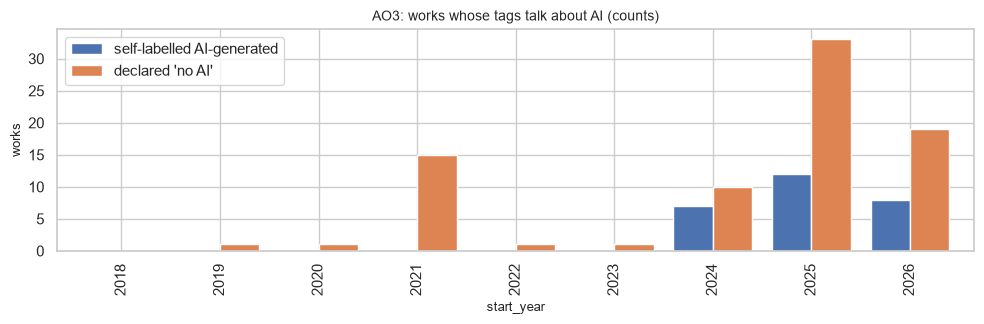

In [26]:
alltags = works["additional_tags"].fillna("")
generated = alltags.str.contains(r"AI-Generated Text|Created Using Generative AI|Written with ChatGPT", case=False, regex=True)
declared_human = alltags.str.contains(r"Not Written by AI|\bno AI\b|NO AI WAS USED|No AI generated|No AI Used|\bnot AI\b|zero AI|"
                                      r"do not use AI|don.t use (?:for )?AI", case=False, regex=True) & ~generated
ai = pd.DataFrame({"self-labelled AI-generated": generated, "declared 'no AI'": declared_human}).groupby(works["start_year"]).sum()
ax = ai.loc[2018:].plot(kind="bar", figsize=(10, 3.4), width=0.8)
ax.set_title("AO3: works whose tags talk about AI (counts)")
ax.set_ylabel("works")
plt.tight_layout()
plt.show()

<!-- obs:ao3_ai_tags -->
**What we see:**
- Works **self-labelled as AI-generated** appear only from 2024 (7, 12 and 8 works per start year).
  **"No AI" declarations** grow to 33 works started in 2025.
- The 15 "no AI" works started in 2021 got the tag later: **tags are a snapshot from scraping time (2026),
  not from posting time**. The same holds for kudos, hits, comments, bookmarks and completion status.

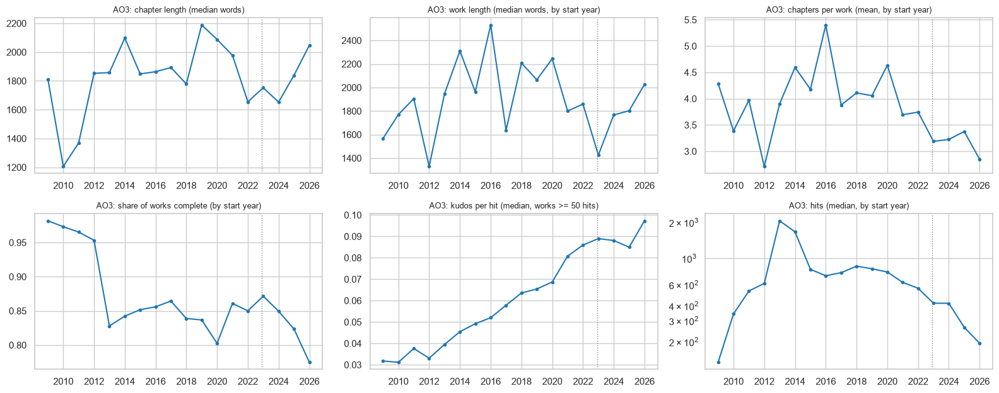

In [27]:
length = pd.DataFrame({
    "chapter length (median words)": ao3.groupby("year")["chapter_word_count"].median(),
    "work length (median words, by start year)": works.groupby("start_year")["word_count"].median(),
    "chapters per work (mean, by start year)": works.groupby("start_year")["chapters_posted"].mean(),
    "share of works complete (by start year)": works.groupby("start_year")["status"].apply(lambda s: s.eq("Complete Work").mean()),
})
engaged = works[works["hits"] >= 50]
length["kudos per hit (median, works >= 50 hits)"] = (engaged["kudos"].fillna(0) / engaged["hits"]).groupby(engaged["start_year"]).median()
length["hits (median, by start year)"] = works.groupby("start_year")["hits"].median()
fig, axes = plt.subplots(2, 3, figsize=(16, 6.4))
for ax, column in zip(axes.flat, length.columns):
    ax.plot(length.index, length[column], "-o", ms=3, color="tab:blue")
    ax.axvline(BREAK, color="0.5", ls=":", lw=1)
    ax.set_title(f"AO3: {column}", fontsize=9)
    int_years(ax)
axes.flat[-1].set_yscale("log")
fig.tight_layout()
plt.show()

<!-- obs:ao3_lengths -->
**What we see:**
- The median chapter has ~1,800–2,200 words, with a dip in 2022–2024 (~1,650) and back to ~2,050 in 2026.
  Work length is noisy (1,400–2,500 words).
- Recent works have fewer chapters and are less often complete because **they are still being written**
  (right-censoring), not because of a change in style.
- **Kudos per hit rises steadily (0.03 → 0.097)** and hits fall for recent works. Engagement depends on a
  work's age, so it is not comparable across years without correction.

## 2.3 From raw data to the analysed corpus

,step,description,documents_changed,documents_dropped,documents_remaining
0,duplicates,duplicate chapters (same chapter_id),0,55908,163359
1,podfics,podfic chapters,0,681,162678
2,chapter_heading,'Chapter Text' heading,132416,0,162678
3,notes,author notes / headers / sign-offs,11850,0,162678
4,scene_breaks,scene-break lines,24304,0,162678
5,urls_emoji,"URLs, e-mails, emoji",1535,0,162678
6,markdown,markdown asterisks,2890,0,162678
7,tidy,tidy whitespace,18364,0,162678
8,window,windows under 400 words,0,20822,141856


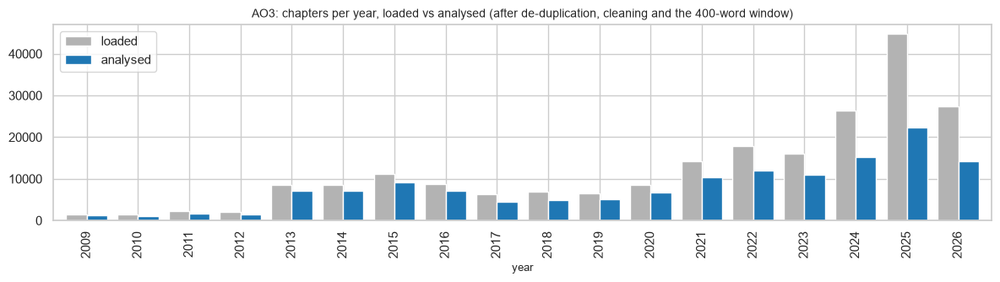

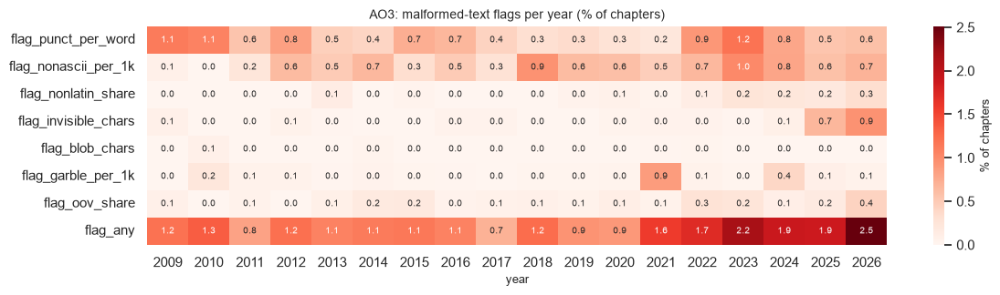

In [28]:
CORPUS = ROOT / "outputs/ao3/corpus"
display(pd.read_csv(CORPUS / "cleaning_report.csv")[["step", "description", "documents_changed", "documents_dropped", "documents_remaining"]])
before = pd.read_csv(CORPUS / "documents_by_year_raw.csv", index_col=0).iloc[:, 0]
after = pd.read_csv(CORPUS / "documents_by_year.csv", index_col=0).iloc[:, 0]
ax = pd.DataFrame({"loaded": before, "analysed": after}).fillna(0).plot(kind="bar", figsize=(12, 3.5), width=0.8, color=["0.7", "tab:blue"])
ax.set_title("AO3: chapters per year, loaded vs analysed (after de-duplication, cleaning and the 400-word window)")
plt.tight_layout()
plt.show()
flags = pd.read_csv(CORPUS / "quality_flags_by_year.csv", index_col=0).drop(columns="documents")
fig, ax = plt.subplots(figsize=(12, 3.4))
sns.heatmap(flags.T, annot=True, fmt=".1f", annot_kws={"size": 7}, cmap="Reds", ax=ax, cbar_kws={"label": "% of chapters"})
ax.set_title("AO3: malformed-text flags per year (% of chapters)")
fig.tight_layout()
plt.show()

<!-- obs:ao3_prepare -->
**What we see:**
- From 163,359 chapters after de-duplication, 681 podfics and 20,822 chapters under 400 words are removed:
  **141,856 chapters are analysed** (87%).
- The "loaded" counts per year include duplicates, so the analysed share looks lower for 2024–26 (the
  umbrella file overlaps the others).
- Malformed-text flags affect 1–2.5% of chapters, rising slowly; invisible characters reach 0.7–0.9% in
  2025–26.

## 2.4 The Biber features across the years
Same standardisation as for ACL, with AO3's own scaler (66 features: the split infinitive, almost
always zero, is excluded).

141,844 chapters x 66 features; years 2009–2026


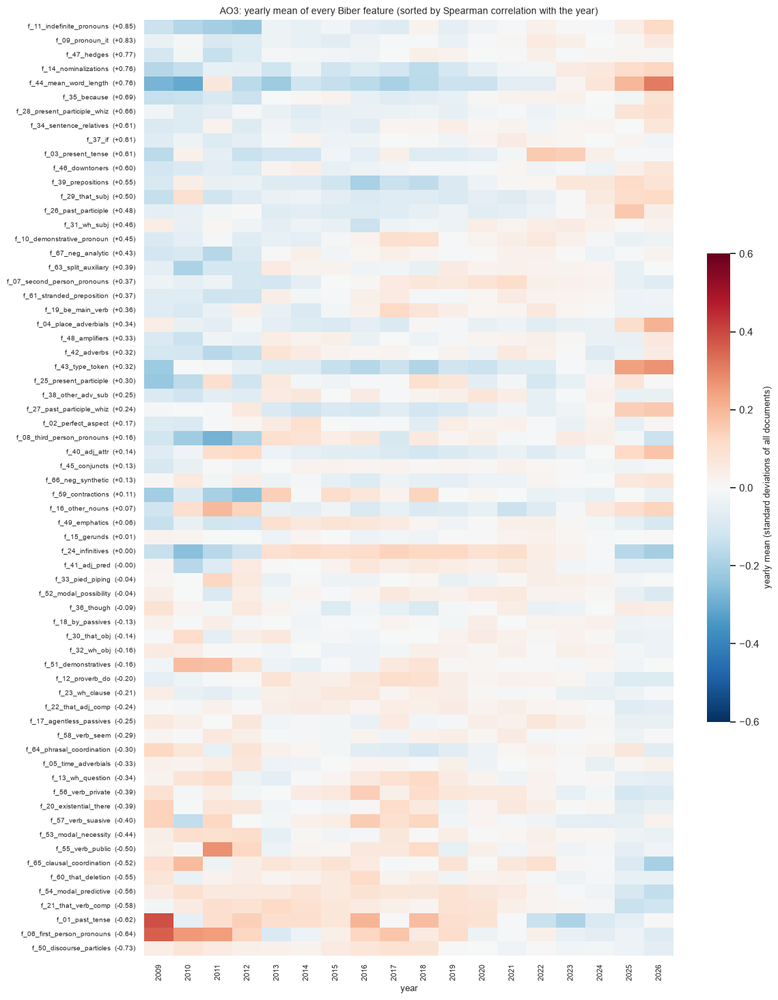

In [29]:
RESULTS = ROOT / "outputs/ao3/results"
ao3_docs = pd.read_parquet(ROOT / "outputs/ao3/corpus/corpus.parquet", columns=["chapter_id", "chapter_date", "year", "rating", "fandoms"])
ao3_features = pd.read_parquet(ROOT / "outputs/ao3/features/biber_features.parquet")
common = ao3_docs.index.intersection(ao3_features.index)
ao3_docs, ao3_features = ao3_docs.loc[common], ao3_features.loc[common]
scaler = pd.read_csv(RESULTS / "reference_scaler.csv", index_col=0)
ao3_z = (ao3_features[scaler.index] - scaler["mean"]) / scaler["std"]
ao3_years = ao3_docs["year"].astype(int)
AO3_YEARS = ao3_years.value_counts().loc[lambda s: s >= 100].index.sort_values()
ao3_yearly = yearly_z(ao3_z, ao3_years, AO3_YEARS)
print(f"{len(ao3_z):,} chapters x {ao3_z.shape[1]} features; years {AO3_YEARS.min()}–{AO3_YEARS.max()}")
trend_heatmap(ao3_yearly, "AO3: yearly mean of every Biber feature (sorted by Spearman correlation with the year)")
plt.show()

<!-- obs:ao3_heatmap -->
**What we see:**
- **Much smaller changes than ACL** (paler colours: yearly means rarely move more than ±0.2 sd, although
  some features correlate with the year up to ρ = 0.85). Two periods stand out:
  - **2009–2012**: few, older-style stories with more past tense and first-person pronouns.
  - **2025–2026**: word length, type-token ratio, nominalizations, place adverbials and attributive
    adjectives are up; clausal coordination and predictive modals are down.

,change per decade (sd),Spearman rho with year,direction
f_44_mean_word_length,0.224,0.756,rising
f_11_indefinite_pronouns,0.142,0.853,rising
f_14_nominalizations,0.131,0.765,rising
f_43_type_token,0.127,0.321,rising
f_39_prepositions,0.093,0.554,rising
f_03_present_tense,0.093,0.612,rising
f_35_because,0.090,0.688,rising
f_08_third_person_pronouns,0.082,0.156,rising
f_06_first_person_pronouns,-0.175,-0.643,falling
f_01_past_tense,-0.162,-0.620,falling


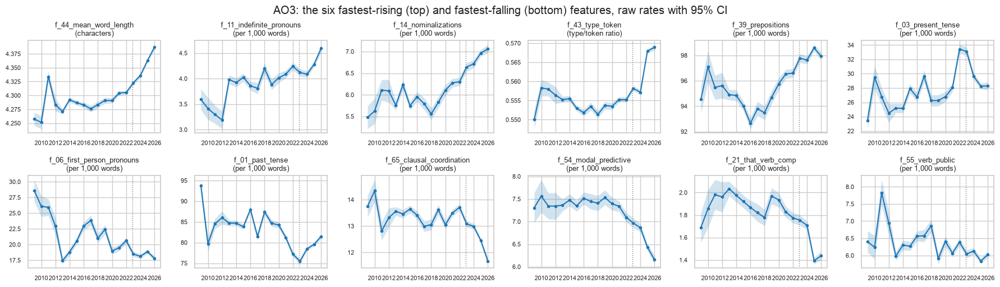

In [30]:
table = trend_table(ao3_yearly).sort_values("change per decade (sd)")
display(pd.concat([table.tail(8)[::-1].assign(direction="rising"), table.head(8).assign(direction="falling")]).round(3))
top = list(table.tail(6).index[::-1]) + list(table.head(6).index)
mean, half = mean_ci(ao3_features[top], ao3_years)
line_panels(mean, half, top, [f"{f}\n({feature_unit(f)})" for f in top], ncols=6, panel=(3.0, 2.5))
plt.suptitle("AO3: the six fastest-rising (top) and fastest-falling (bottom) features, raw rates with 95% CI", y=1.02)
plt.show()

<!-- obs:ao3_top_features -->
**What we see:**
- **Rising**: word length 4.26 → 4.39 (mostly since 2022), indefinite pronouns 3.2 → 4.6, nominalizations
  5.5 → 7.1, prepositions 93 → 98 (since 2016). Type-token ratio is flat at ~0.552–0.558 until 2024, then
  **0.568 in 2025**. Present tense peaks in 2022–23 (33 per 1,000 words).
- **Falling**: first-person pronouns 28.5 → 17.8 (mostly 2009–2013), past tense 94 → 75 (2023) and back to
  81, clausal coordination 14 → 11.7, predictive modals 7.5 → 6.2, *that*-clauses 2.0 → 1.4 (sharp drop in
  2025).

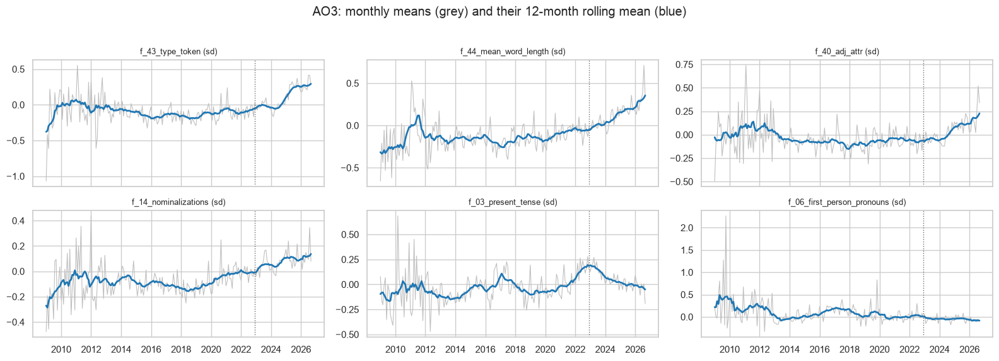

In [31]:
months = pd.to_datetime(ao3_docs["chapter_date"], errors="coerce").dt.to_period("M")
watch = ["f_43_type_token", "f_44_mean_word_length", "f_40_adj_attr", "f_14_nominalizations", "f_03_present_tense", "f_06_first_person_pronouns"]
monthly = ao3_z[watch].groupby(months).mean()
monthly.index = monthly.index.to_timestamp()
fig, axes = plt.subplots(2, 3, figsize=(16, 5.6), sharex=True)
for ax, column in zip(axes.flat, watch):
    ax.plot(monthly.index, monthly[column], color="0.75", lw=0.8)
    ax.plot(monthly.index, monthly[column].rolling(12, center=True, min_periods=6).mean(), color="tab:blue", lw=2)
    ax.axvline(pd.Timestamp("2022-11-30"), color="0.4", ls=":", lw=1)
    ax.set_title(f"{column} (sd)", fontsize=9)
fig.suptitle("AO3: monthly means (grey) and their 12-month rolling mean (blue)", y=1.02)
fig.tight_layout()
plt.show()

<!-- obs:ao3_monthly -->
**What we see:**
- **The change is gradual, not a jump at ChatGPT's release.** Word length climbs from ~2021 and
  accelerates; nominalizations rise slowly from ~2019; attributive adjectives rise from mid-2024; the
  type-token ratio steps up in early 2025.
- Present tense peaks at the end of 2022 and in 2023, then falls back. First-person pronouns fell in
  2009–2013 and have stayed flat since.

### Feature change between the key years: absolute, relative and combined
From the pipeline's `feature_change` analysis (`outputs/ao3/results/feature_change/all/`). For each step
between the key years (2009 → 2019 → 2025) and the full span, the **top 10 features** are ranked three ways:

1. **Absolutely**: the difference of the yearly means, in the feature's own unit (per 1,000 words, except
   the type-token ratio and the word length). This favours frequent features (nouns, prepositions, tenses).
2. **Relatively**: the difference as a percentage of the earlier mean. This favours rare features.
3. **Combined**: both magnitudes min-max scaled to 0–1 across all features and averaged (0.5 each), as in
   the original AO3 notebook. A feature ranks high only if it changes a lot in both senses.

Bar colour gives the direction (blue: the mean increased, orange: it decreased).

#### AO3: 2009 → 2019

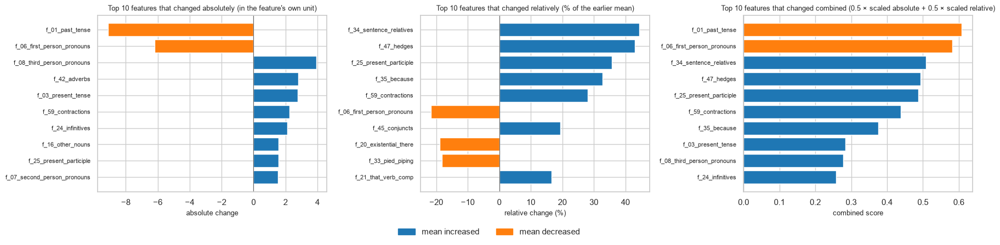

,absolutely,relatively,combined
rank,,,
1,f_01_past_tense (-9.11),f_34_sentence_relatives (+44%),f_01_past_tense (0.61)
2,f_06_first_person_pronouns (-6.19),f_47_hedges (+43%),f_06_first_person_pronouns (0.58)
3,f_08_third_person_pronouns (+3.93),f_25_present_participle (+36%),f_34_sentence_relatives (0.51)
4,f_42_adverbs (+2.79),f_35_because (+33%),f_47_hedges (0.49)
5,f_03_present_tense (+2.77),f_59_contractions (+28%),f_25_present_participle (0.49)
6,f_59_contractions (+2.26),f_06_first_person_pronouns (-22%),f_59_contractions (0.44)
7,f_24_infinitives (+2.10),f_45_conjuncts (+19%),f_35_because (0.37)
8,f_16_other_nouns (+1.57),f_20_existential_there (-19%),f_03_present_tense (0.28)
9,f_25_present_participle (+1.56),f_33_pied_piping (-18%),f_08_third_person_pronouns (0.28)


#### AO3: 2019 → 2025

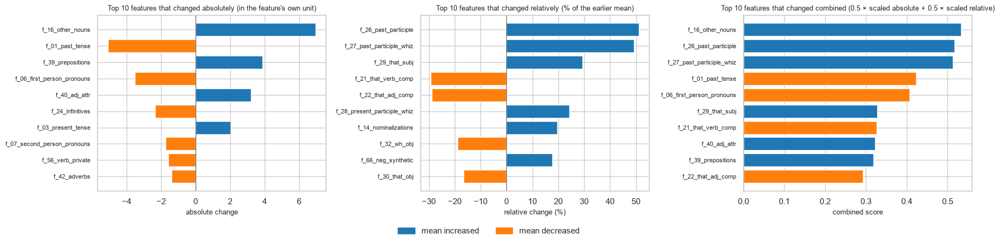

,absolutely,relatively,combined
rank,,,
1,f_16_other_nouns (+6.97),f_26_past_participle (+51%),f_16_other_nouns (0.53)
2,f_01_past_tense (-5.08),f_27_past_participle_whiz (+49%),f_26_past_participle (0.52)
3,f_39_prepositions (+3.89),f_29_that_subj (+29%),f_27_past_participle_whiz (0.51)
4,f_06_first_person_pronouns (-3.53),f_21_that_verb_comp (-29%),f_01_past_tense (0.42)
5,f_40_adj_attr (+3.22),f_22_that_adj_comp (-29%),f_06_first_person_pronouns (0.41)
6,f_24_infinitives (-2.34),f_28_present_participle_whiz (+24%),f_29_that_subj (0.33)
7,f_03_present_tense (+2.02),f_14_nominalizations (+20%),f_21_that_verb_comp (0.33)
8,f_07_second_person_pronouns (-1.75),f_32_wh_obj (-19%),f_40_adj_attr (0.32)
9,f_56_verb_private (-1.58),f_66_neg_synthetic (+18%),f_39_prepositions (0.32)


#### AO3: 2009 → 2025

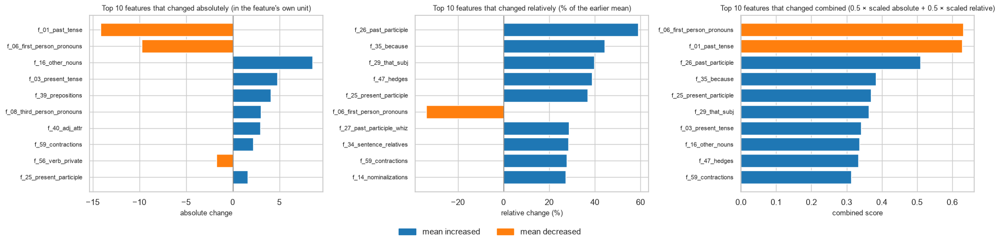

,absolutely,relatively,combined
rank,,,
1,f_01_past_tense (-14.18),f_26_past_participle (+59%),f_06_first_person_pronouns (0.63)
2,f_06_first_person_pronouns (-9.72),f_35_because (+44%),f_01_past_tense (0.63)
3,f_16_other_nouns (+8.54),f_29_that_subj (+40%),f_26_past_participle (0.51)
4,f_03_present_tense (+4.79),f_47_hedges (+39%),f_35_because (0.38)
5,f_39_prepositions (+4.06),f_25_present_participle (+37%),f_25_present_participle (0.37)
6,f_08_third_person_pronouns (+3.04),f_06_first_person_pronouns (-34%),f_29_that_subj (0.36)
7,f_40_adj_attr (+3.00),f_27_past_participle_whiz (+29%),f_03_present_tense (0.34)
8,f_59_contractions (+2.23),f_34_sentence_relatives (+28%),f_16_other_nouns (0.34)
9,f_56_verb_private (-1.73),f_59_contractions (+28%),f_47_hedges (0.33)


In [32]:
show_feature_change(ROOT / "outputs/ao3", "AO3")

<!-- obs:ao3_feature_change -->
**What we see:**
- **2009 → 2019**: the biggest change is **narration**: less past tense (−9.1 per 1,000 words) and fewer
  first-person pronouns (−6.2), more third-person pronouns (+3.9) and present tense (+2.8). Relatively,
  rare features such as sentence relatives (+44%), hedges (+43%) and present participles (+36%) grow.
- **2019 → 2025**: the change turns **nominal and descriptive**: nouns (+7.0), prepositions (+3.9) and
  attributive adjectives (+3.2) rise while past tense (−5.1) and first person (−3.5) keep falling.
  Relatively, past-participle clauses (+51%) and reduced participle clauses (+49%) grow, and
  *that*-clauses fall (about −29%). Nouns lead the combined ranking.
- Over the full span (2009 → 2025), the combined top features are first-person pronouns, past tense,
  past participles, *because* and present participles.
- Relative changes in AO3 stay within ±59%, against up to +337% in ACL: fan fiction changes much less
  than the papers.

## 2.5 Biber's seven dimensions across the years

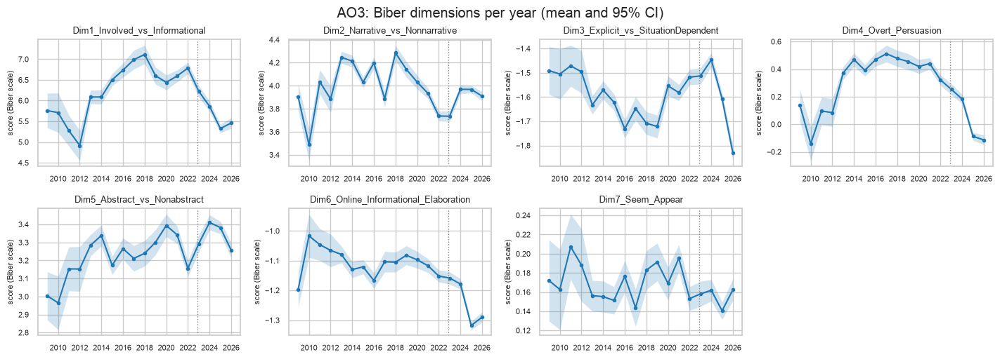

In [33]:
ao3_dims = BiberDimensionScorer("biber1988", include_seem_appear=True).score(ao3_features)
mean, half = mean_ci(ao3_dims, ao3_years)
line_panels(mean, half, list(ao3_dims.columns), ncols=4, ylabel="score (Biber scale)")
plt.suptitle("AO3: Biber dimensions per year (mean and 95% CI)", y=1.02)
plt.show()

<!-- obs:ao3_dimensions -->
**What we see:**
- **Dimension 1** (involved) rises from 4.9 (2012) to 7.1 (2018), then falls to 5.3 (2025): recent stories
  are less conversational.
- **Dimension 4** (persuasion) peaks in 2017 (0.5) and falls to −0.1 by 2025–26. Dimension 3 peaks in 2024
  and drops sharply in 2025–26. Dimension 6 drops in 2025.

## 2.6 How similar are the years to each other?
Pairwise MMD² between fixed samples of 600 chapters per year.

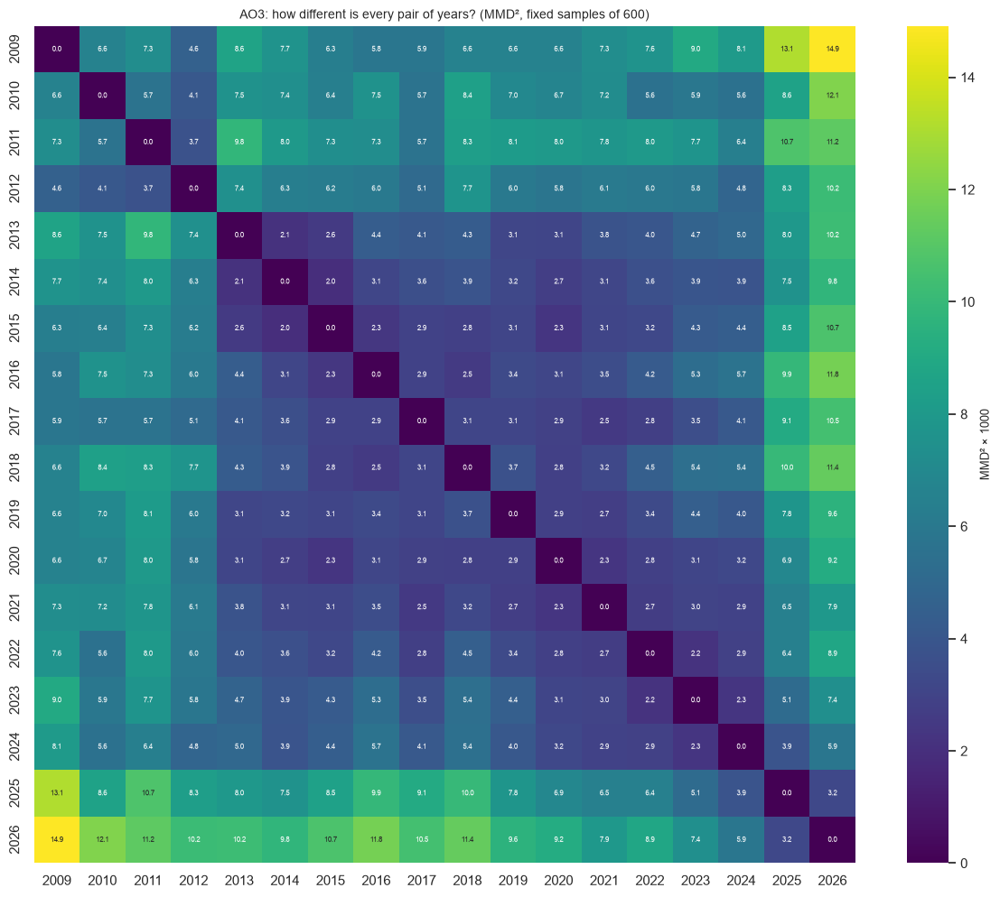

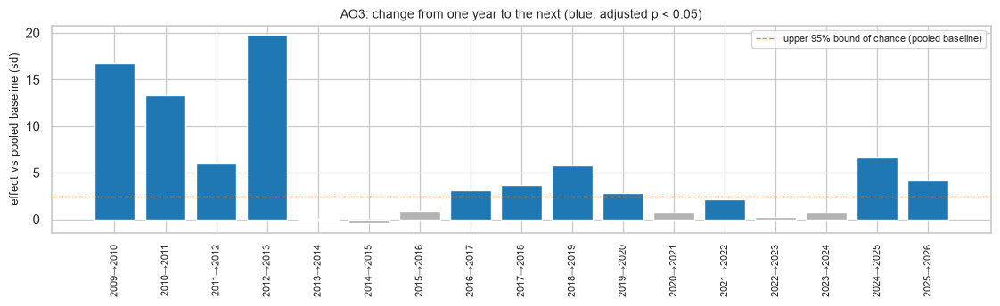

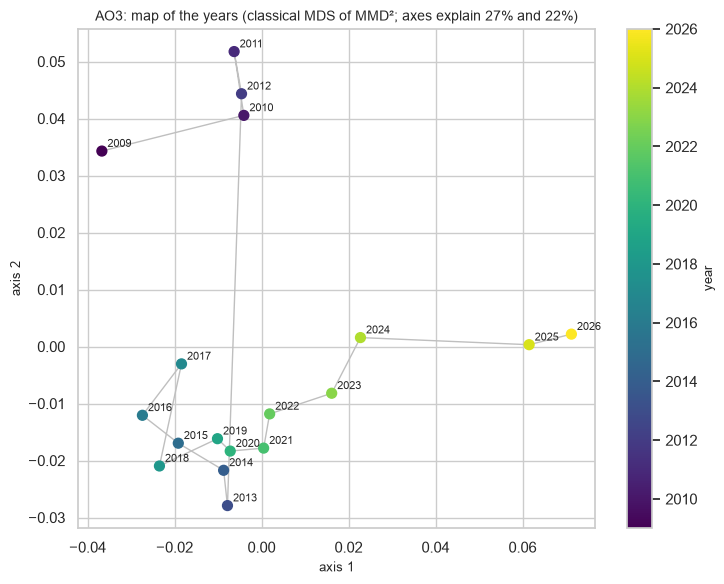

In [34]:
ao3_matrix, ao3_steps = mmd_figures(RESULTS, "AO3")

<!-- obs:ao3_mmd -->
**What we see:**
- **Three eras**: 2009–2012 (few chapters, different stories); a stable 2013–2024 block, in which most
  neighbouring years are at chance level; and **2025–2026, far from all earlier years**.
- The large steps are in the early years (2009 → 2013: up to 19.8, small early years plus the *Hobbit*
  influx), small ones in 2016–2020 (3–6), and **2024 → 2025 (6.6) and 2025 → 2026 (4.2)**. The 2021
  coverage change shows only as small steps (0.7 and 2.1).
- On the map: 2009–2012 at the top, 2013–2022 in a compact cluster, then a path 2022 → 2023 → 2024 →
  2025/2026 to the right.

## 2.7 The style space: where does each year sit?

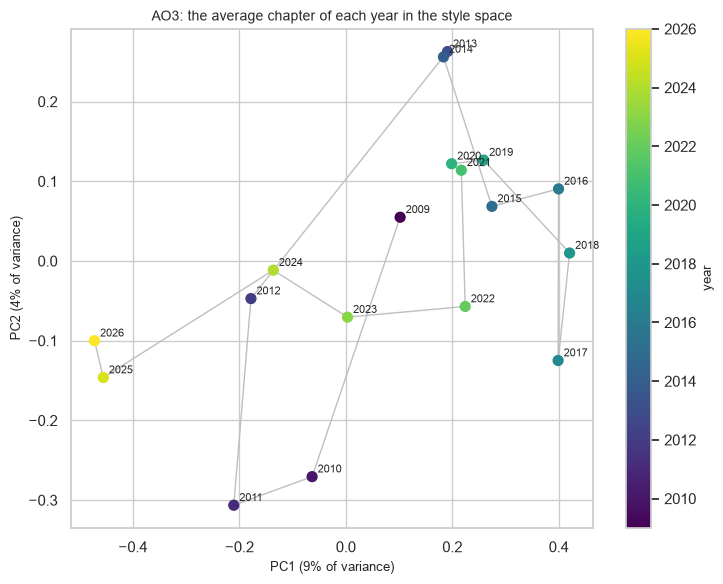

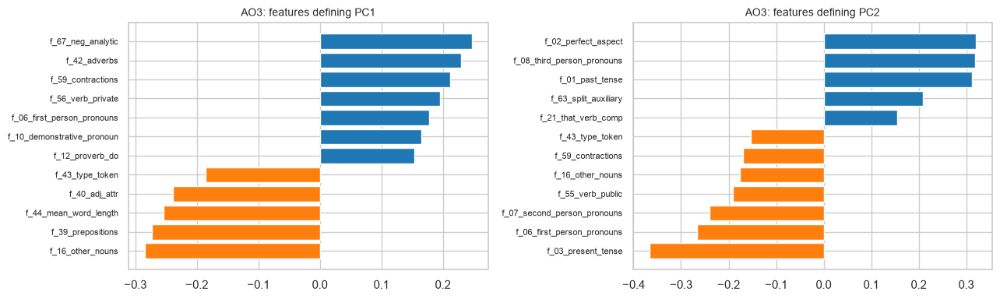

In [35]:
scores, loadings, explained = pca(ao3_z)
centroids = scores.groupby(ao3_years).mean().loc[AO3_YEARS]
plot_trajectory(centroids.to_numpy(), list(AO3_YEARS), "AO3: the average chapter of each year in the style space",
                f"PC1 ({explained[0]:.0%} of variance)", f"PC2 ({explained[1]:.0%} of variance)")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    top_loadings = loadings[pc].reindex(loadings[pc].abs().nlargest(12).index).sort_values()
    ax.barh(top_loadings.index, top_loadings.values, color=np.where(top_loadings.values > 0, "tab:blue", "tab:orange"))
    ax.set_title(f"AO3: features defining {pc}")
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()

<!-- obs:ao3_pca -->
**What we see:**
- **2025–2026 sit at the "informational" end of PC1** (nouns, prepositions, word length, attributive
  adjectives, type-token ratio), away from the "involved" end (negation, adverbs, contractions, private
  verbs, first-person pronouns). The path from 2021 to 2025 moves steadily that way.
- **PC2** separates past-tense, third-person narration from present tense with first and second person.

## 2.8 Diversity: are the chapters of a year becoming more alike?

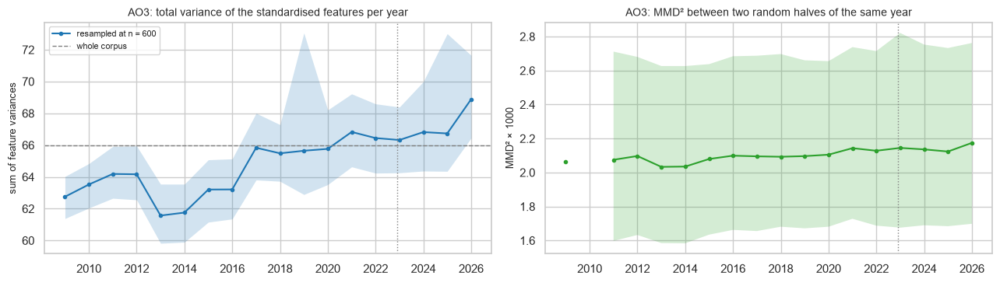

In [36]:
diversity_figure(RESULTS, "AO3")

<!-- obs:ao3_diversity -->
**What we see:**
- **The opposite of ACL**: total variance rises from ~61.5 (2013) to **68.9 (2026)**, so fan fiction is
  becoming *more* varied.
- The within-year MMD² stays flat (~2.1 × 10⁻³).

## 2.9 Who writes what: style by rating and by reader-insert stories
Reader-insert stories ("x Reader") are written to "you"; they show whether the pronoun trends come
from a change in the kind of stories posted.

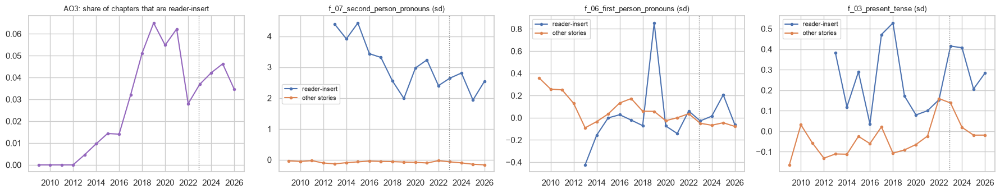

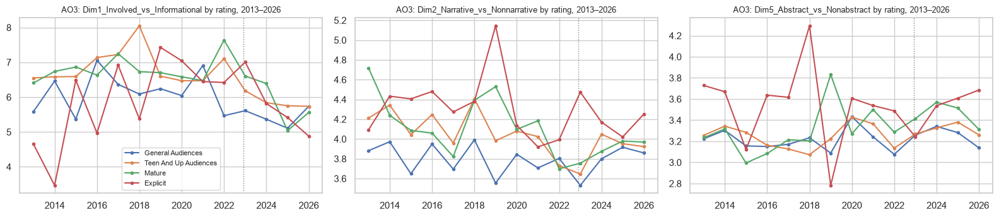

In [37]:
extra = ao3.set_index("chapter_id")[["characters", "relationships"]]
tagged = ao3_docs[["chapter_id"]].astype({"chapter_id": str}).join(extra, on="chapter_id")
reader = (tagged["characters"].fillna("") + ";" + tagged["relationships"].fillna("")).str.contains(r"\bReader\b", regex=True)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
share = reader.groupby(ao3_years).mean()
axes[0].plot(share.index, share.values, "-o", ms=3, color="tab:purple")
axes[0].set_title("AO3: share of chapters that are reader-insert", fontsize=9)
for ax, column in zip(axes[1:], ["f_07_second_person_pronouns", "f_06_first_person_pronouns", "f_03_present_tense"]):
    for label, mask in [("reader-insert", reader), ("other stories", ~reader)]:
        series = ao3_z.loc[mask, column].groupby(ao3_years[mask]).mean()
        ax.plot(series.index, series.values, "-o", ms=3, label=label)
    ax.set_title(f"{column} (sd)", fontsize=9)
    ax.legend(fontsize=8)
for ax in axes:
    ax.axvline(BREAK, color="0.5", ls=":", lw=1)
    int_years(ax)
fig.tight_layout()
plt.show()

rating = ao3_docs["rating"].fillna("Not Rated")
since = ao3_years >= 2013   # earlier years have too few chapters per rating
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, column in zip(axes, ["Dim1_Involved_vs_Informational", "Dim2_Narrative_vs_Nonnarrative", "Dim5_Abstract_vs_Nonabstract"]):
    for label in ["General Audiences", "Teen And Up Audiences", "Mature", "Explicit"]:
        mask = (rating == label) & since
        series = ao3_dims.loc[mask, column].groupby(ao3_years[mask]).mean()
        ax.plot(series.index, series.values, "-o", ms=3, label=label)
    ax.axvline(BREAK, color="0.5", ls=":", lw=1)
    int_years(ax)
    ax.set_title(f"AO3: {column} by rating, 2013–2026", fontsize=9)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

<!-- obs:ao3_groups -->
**What we see:**
- **Reader-insert stories** go from none before 2013 to a peak of ~6.5% of chapters (2019) and 3–5% since 2023.
  They use **2–4.4 sd more second-person pronouns**: a sanity check that the features measure what they claim.
- The fall in first-person pronouns happens in ordinary stories, so it is not caused by reader-inserts.
  Present tense peaks in 2022–23 in both groups.
- By rating (2013–2026), the dimension trends are similar for all ratings; Explicit is the noisiest
  (fewest chapters).

## 2.10 Does the recent change happen inside each fandom?
From 2024 the umbrella-tag file adds most chapters (section 2.1), so the mix of the data changes.
Grouping chapters by their **fandom tags** (a chapter can carry several) shows whether the features
move within each canon too.

share of chapters tagged with none of the three canons, 2022–2026: {2022: 0.001, 2023: 0.0, 2024: 0.004, 2025: 0.02, 2026: 0.011}


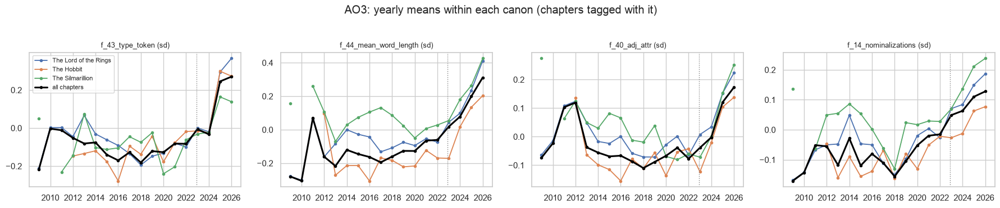

,f_43_type_token,f_44_mean_word_length,f_40_adj_attr,f_14_nominalizations
change 2022 → 2025 (sd),,,,
The Lord of the Rings,0.39,0.31,0.22,0.18
The Hobbit,0.32,0.30,0.15,0.08
The Silmarillion,0.23,0.24,0.21,0.18
all chapters,0.33,0.26,0.20,0.13


In [38]:
fandom_tags = ao3_docs["fandoms"].fillna("")
canons = {"The Lord of the Rings": fandom_tags.str.contains("Lord of the Rings", case=False),
          "The Hobbit": fandom_tags.str.contains("Hobbit", case=False),
          "The Silmarillion": fandom_tags.str.contains("Silmarillion", case=False)}
outside = ~(canons["The Lord of the Rings"] | canons["The Hobbit"] | canons["The Silmarillion"])
print("share of chapters tagged with none of the three canons, 2022–2026:",
      outside.groupby(ao3_years).mean().loc[2022:].round(3).to_dict())
watch = ["f_43_type_token", "f_44_mean_word_length", "f_40_adj_attr", "f_14_nominalizations"]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
changes = {}
for ax, column in zip(axes, watch):
    for name, mask in list(canons.items()) + [("all chapters", pd.Series(True, index=ao3_docs.index))]:
        counts = mask.groupby(ao3_years).sum()
        series = ao3_z.loc[mask, column].groupby(ao3_years[mask]).mean().where(counts >= 100)
        ax.plot(series.index, series.values, "-o", ms=3, label=name, color="black" if name == "all chapters" else None,
                lw=2.2 if name == "all chapters" else 1.3)
        changes.setdefault(name, {})[column] = series.get(2025) - series.get(2022)
    ax.axvline(BREAK, color="0.5", ls=":", lw=1)
    int_years(ax)
    ax.set_title(f"{column} (sd)", fontsize=9)
axes[0].legend(fontsize=8)
fig.suptitle("AO3: yearly means within each canon (chapters tagged with it)", y=1.03)
fig.tight_layout()
plt.show()
display(pd.DataFrame(changes).T.round(2).rename_axis("change 2022 → 2025 (sd)"))

<!-- obs:ao3_fandoms -->
**What we see:**
- Only 0.4–2% of the 2024–26 chapters carry none of the three canon tags, so the umbrella file adds hardly
  any other fandoms.
- **The recent rise holds inside each canon**, including the fully covered LotR and Hobbit chapters
  (change 2022 → 2025 in sd):
  - type-token ratio: +0.39 (LotR), +0.32 (Hobbit), +0.23 (Silmarillion)
  - word length: +0.31, +0.30, +0.24
  - attributive adjectives: +0.22, +0.15, +0.21
- **The text itself is not an artefact**: 300 sampled chapters stored in both the umbrella and the LotR file
  have identical text.
- **The change sits in new works**: within 2024, chapters of works created since September 2024 (umbrella
  file) are more "informational" than new chapters of older works.

## 2.11 Figures from the pipeline (`outputs/ao3/figures`)
The figures the pipeline's `report` stage already drew for AO3, grouped by topic.

### Corpus and quality

`documents_by_year.png`: Documents per year after cleaning and the 400-word window.

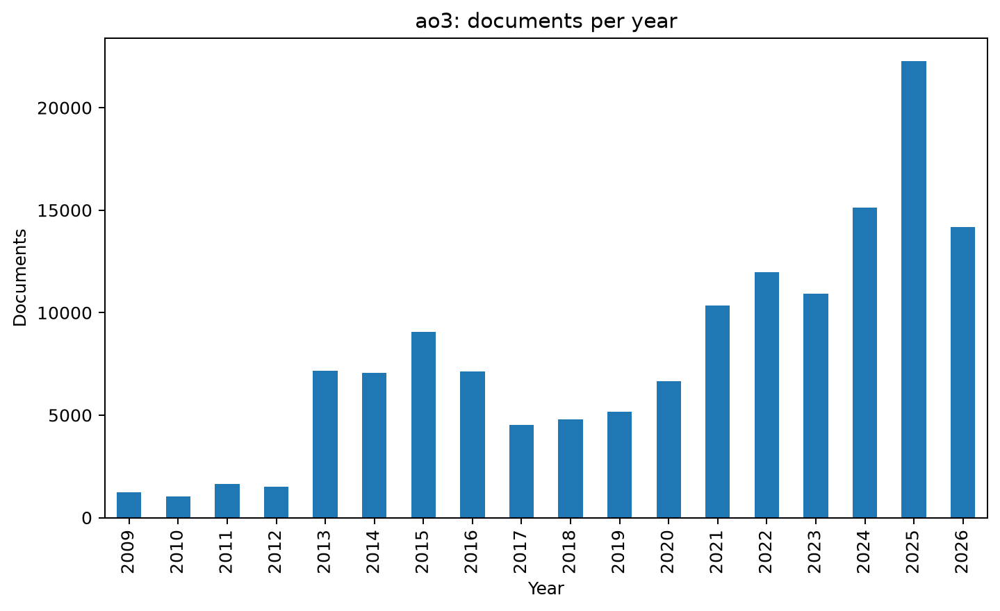

`quality_metrics.png`: Distribution of the seven malformed-text metrics (dashed line: flag threshold).

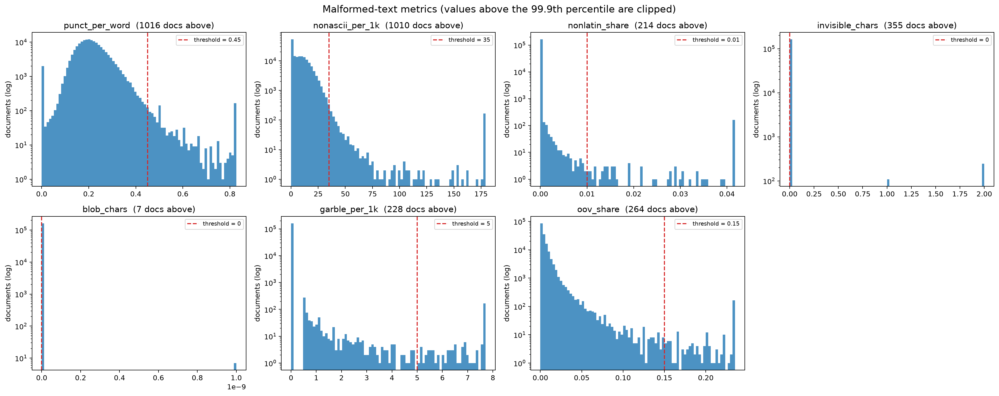

`quality_flags_by_year.png`: Share of documents carrying each quality flag, per year.

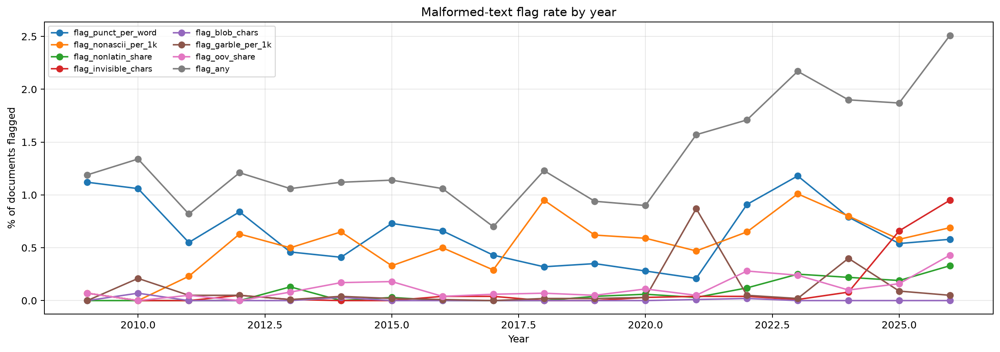

### How different are the years? (MMD²)

`mmd_by_year_heatmap.png`: Pairwise MMD² between the years (fixed samples per year).

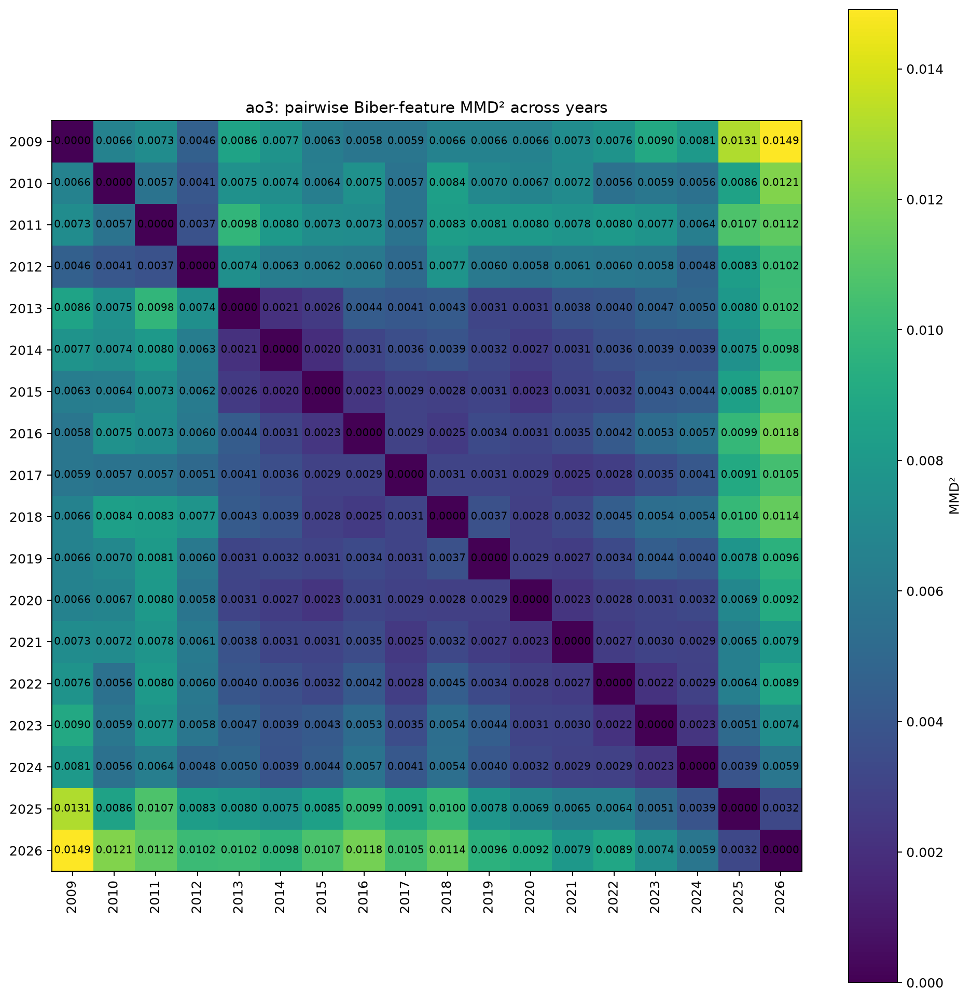

### Sample-size stability (choosing n)

`sample_size_stability_all.png`: MMD² between two random halves against the sample size, whole corpus.

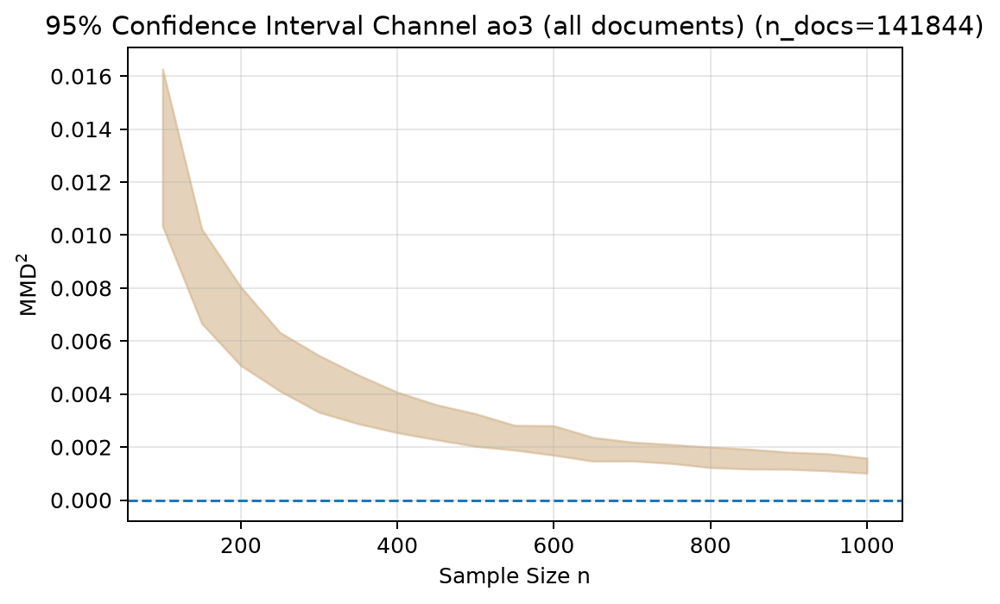

### Biber dimensions

`biber_dimensions_by_year.png`: Dimension scores per year (violins).

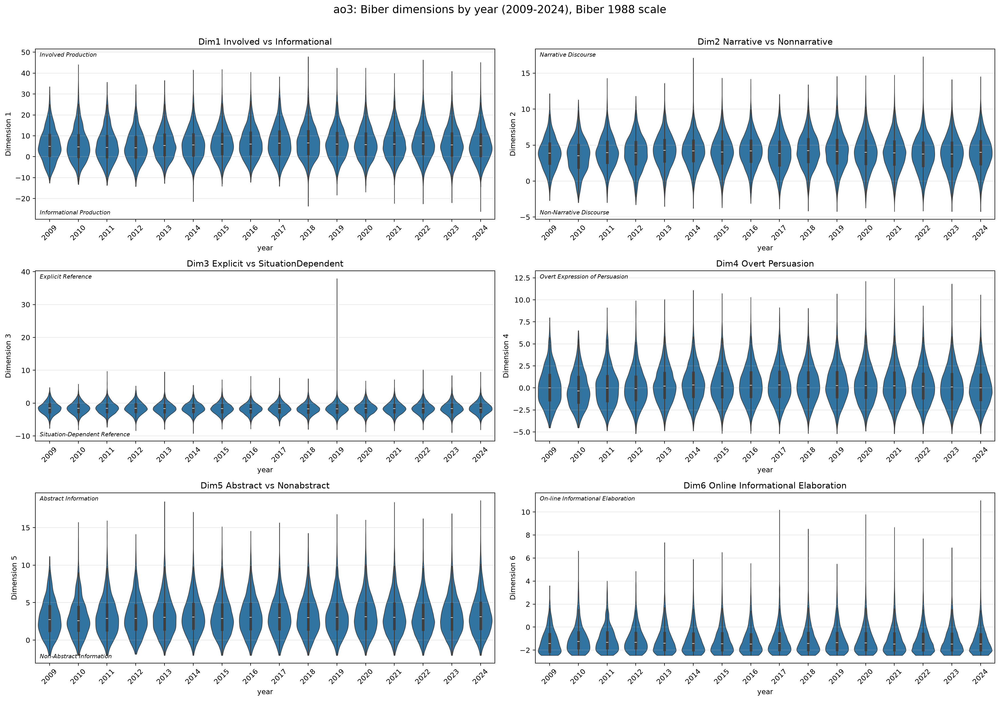

### Feature shifts

`feature_shifts_2009_2019_2025.png`: Largest per-feature shifts (Wasserstein distance) for each key-year step and the full span.

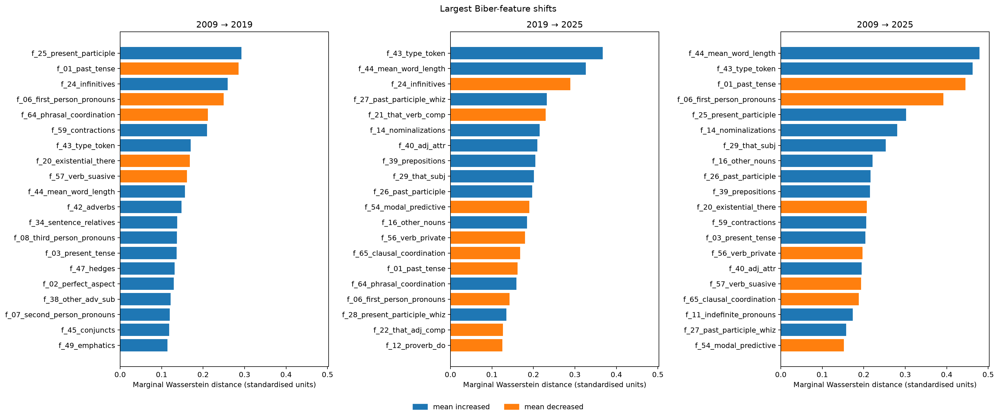

`feature_shifts_2009_2026.png`: Older version of this figure (first vs last year only), left over from an earlier pipeline run.

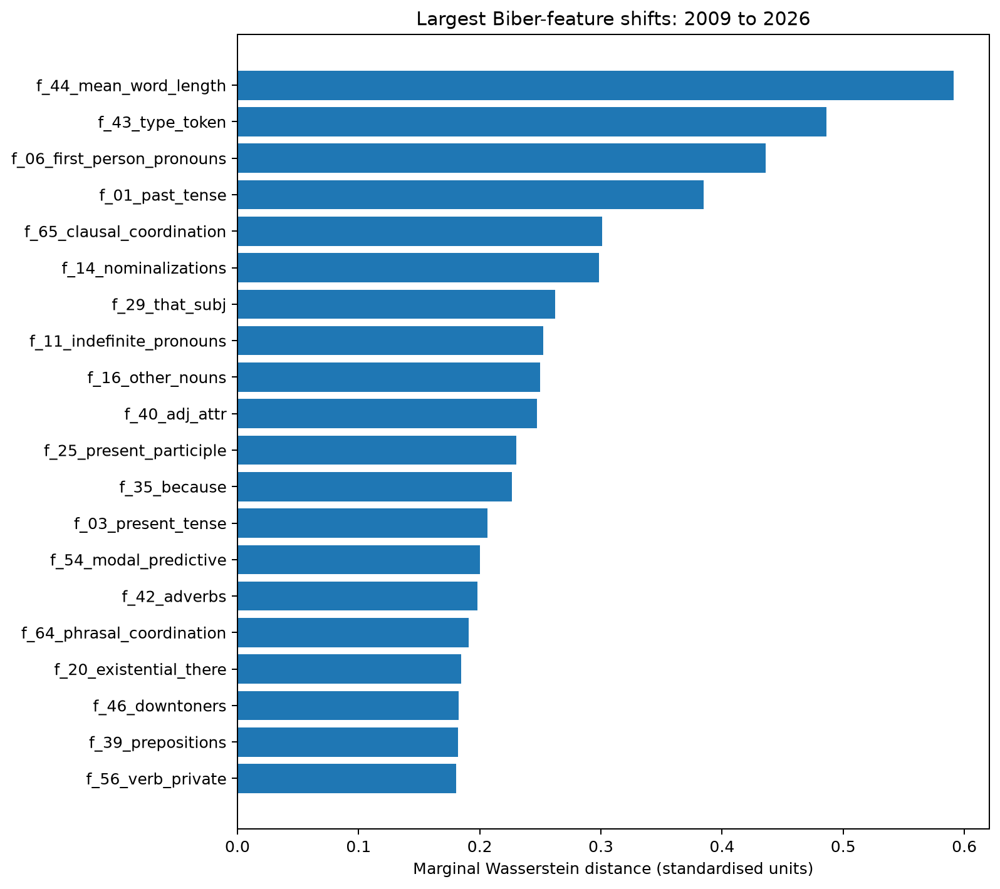

### Diversity

`variance_by_year.png`: Total variance of the standardised features per year.

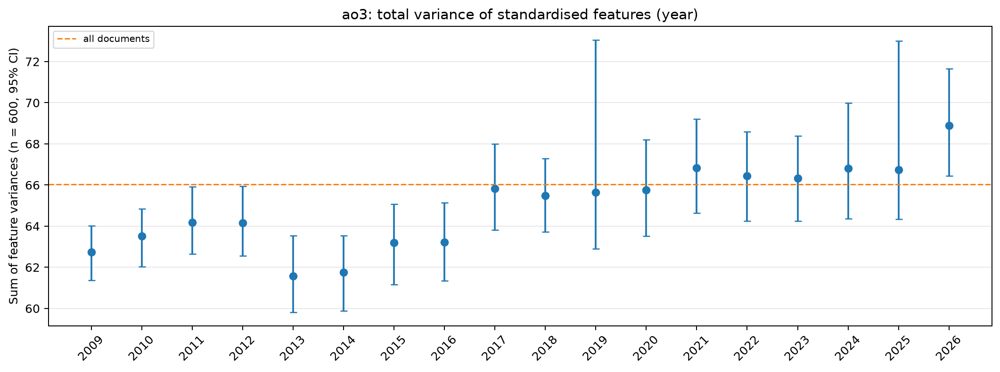

### Interrupted time series

`trend_level_changes.png`: Largest jumps at the break beyond the pre-break trend (features).

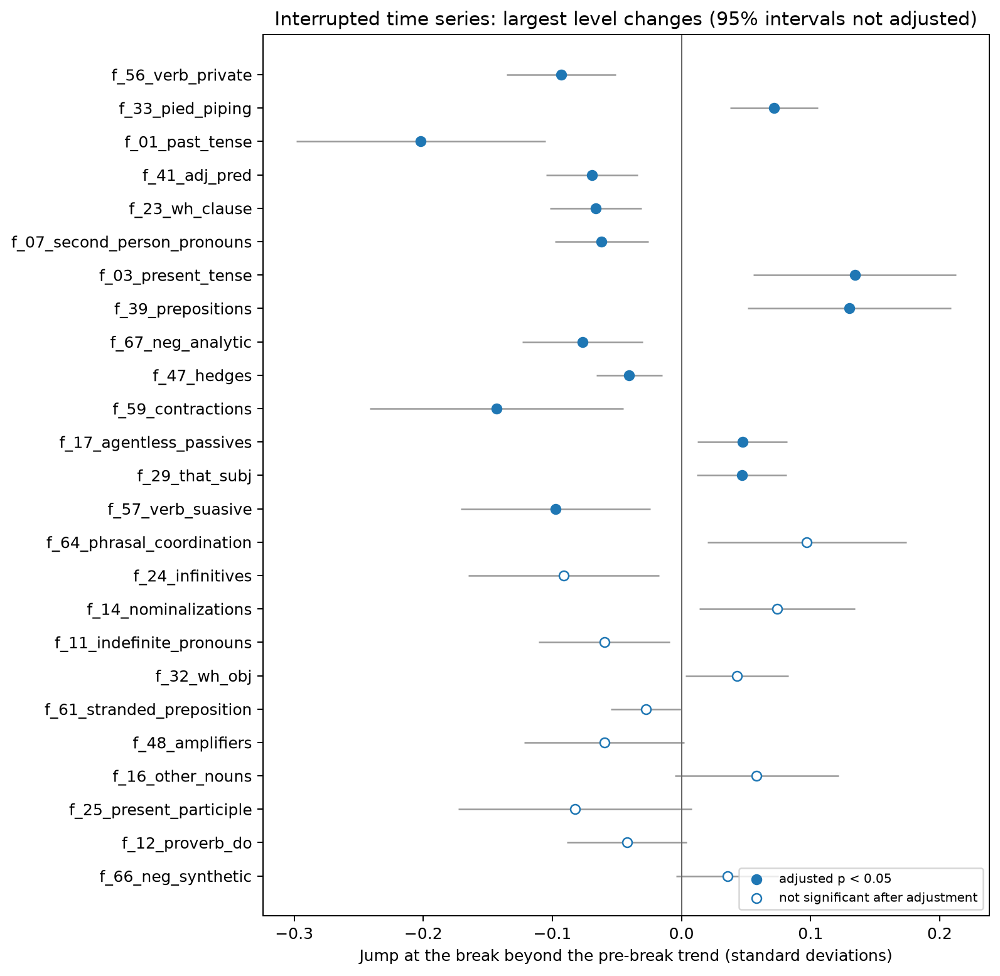

`trend_series_dimensions.png`: Total variance and the seven dimensions with the fitted segmented trend.

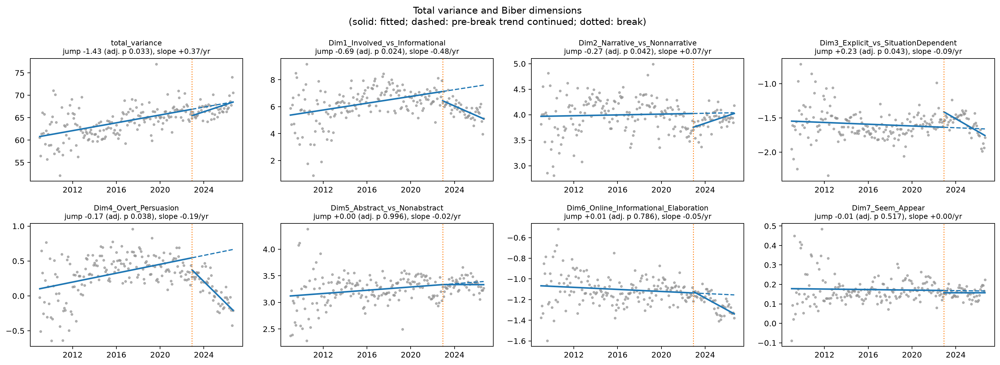

`trend_series_features.png`: The eight features that departed most from their pre-break trend.

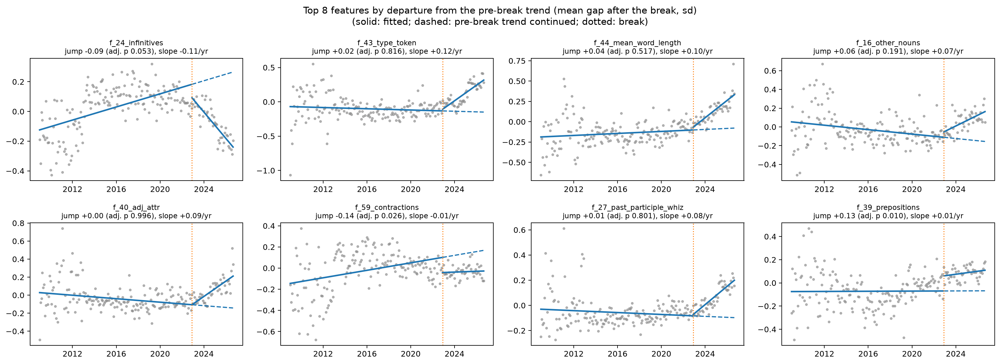

In [39]:
show_pipeline_figures(ROOT / "outputs/ao3/figures")

<!-- obs:summary -->
---
# Summary: candidate analyses

The two corpora tell different stories:

- **ACL papers** change steadily for 25 years (fewer passives and modals, more nouns, bigger teams, longer
  papers), with a **sudden jump in 2023–24** (participles, word length, type-token ratio) and **growing
  uniformity**.
- **AO3 fan fiction** changes in waves that follow the films and series, then drifts **gradually** towards a
  more "informational" style since ~2022, mainly in new works, and becomes **more varied**.

| ID | Analysis | What it shows | In the pipeline now? | Suggestion |
|---|---|---|---|---|
| **A1** | Raw data overview: columns, papers per year, venues and tiers | coverage gaps (2010–12, 2025–26), empty titles, 2007 venue mix | no | add as a data report |
| **A2** | Paper metadata over time: sections, length, team size, citations | longer papers, 2.5 → 4.6 authors | no | add (cheap) |
| **A3** | Topic keywords per year | topic waves; "LLM" in 43% of 2024 abstracts | no | add: context for the style change |
| **A4** | Cleaning and quality per year | what is dropped; OCR in 2000 | yes (CSVs, figures) | keep |
| **A5** | Feature heatmap + fastest-rising/falling features | which features trend, and how strongly | partly (feature change for key years only) | **add: best single overview** |
| **A6** | Dimensions per year (lines with CI) | Dimensions 1, 2 and 5 shift in 2023–24 | violins for 3 eras only | add yearly lines |
| **A7** | MMD: heatmap, year-to-year steps, map of years | pace of change; 2024 apart | heatmap only | add steps + map |
| **A8** | PCA trajectory of the years | path through the style space | no | add |
| **A9** | Diversity per year | papers become more alike | yes | keep |
| **A10** | Venue tiers over time | tiers move together | partly (era × tier) | optional |
| **A11** | Feature change between the key years: top 10 absolute, relative, combined | which features changed most, by three measures | yes (tables); figures new | keep |
| **A12** | Figures from the pipeline | everything the report stage draws | yes | keep |
| **B1** | Raw data overview + coverage per file and year | duplicates; **Silmarillion only since 2021, umbrella only since Sep 2024** | no | **add: important data caveat** |
| **B2** | Community activity: chapters, works, authors | media-driven waves, 2025 influx | no | add |
| **B3** | Metadata over time: rating, category, canon, genre, AI tags, lengths, engagement | category and canon follow the media; humour declines | no | add selectively (canon, genre) |
| **B4** | Cleaning and quality per year | what is dropped | yes | keep |
| **B5** | Feature heatmap + fastest features + monthly view | gradual drift since ~2022 | partly | **add** |
| **B6** | Dimensions per year | Dimensions 1 and 4 decline | violins per year | add yearly lines |
| **B7** | MMD: heatmap, steps, map | three eras; 2025–26 apart | heatmap only | add steps + map |
| **B8** | PCA trajectory | drift to the "informational" end | no | add |
| **B9** | Diversity per year | fan fiction becomes more varied | yes | keep |
| **B10** | Reader-insert and rating subgroups | validity check; pronoun trend not due to reader-inserts | no | optional |
| **B11** | Trends within each canon | the late drift holds in every canon | no | **add: robustness check** |
| **B12** | Feature change between the key years: top 10 absolute, relative, combined | which features changed most, by three measures | yes (tables); figures new | keep |
| **B13** | Figures from the pipeline | everything the report stage draws | yes | keep |

**Data fixes worth doing first:**
1. Resume the **Silmarillion** and **umbrella** AO3 scrapes from their checkpoints (`biber-drift acquire-ao3`
   with the same arguments), so that every year has the same coverage.
2. Re-extract the **ACL 2010–2012 and 2025** papers from a newer S2ORC release.
3. Backfill the empty ACL `title` field.